# Titanic Analysis 

Data is from kaggle: https://www.kaggle.com/competitions/titanic/data

In part 1 of this analysis, we are mainly concerned with conducting **exploratory data analysis (EDA).**

Contents: 
* Data Description
* Data Overview
* Missing Values Analysis
* Target Value Analysis
* Univariate Analysis 
* Bivariate Analysis
* Correlation Analysis
* Key Findings

In [250]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# set plotting style
plt.style.use('bmh')

print('import ok!')

import ok!


## Data Description

| Column | Description |
|---|---|
| `PassengerId` | Unique ID for each passenger |
| `Survived` | Whether the passenger survived (0 = No, 1 = Yes) |
| `Pclass` | Ticket class (1 = Upper, 2 = Middle, 3 = Lower) |
| `Name` | Passenger's full name, including title |
| `Sex` | Passenger's sex |
| `Age` | Age in years |
| `SibSp` | Number of siblings or spouses aboard |
| `Parch` | Number of parents or children aboard |
| `Ticket` | Ticket number |
| `Fare` | Passenger fare (British pounds) |
| `Cabin` | Cabin number |
| `Embarked` | Port of embarkation (C = Cherbourg, Q = Queenstown, S = Southampton) |


## Data Overview

Let's begin by running some methods to get an overview of our dataset.

In [251]:
df = pd.read_csv('titanic.csv')
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [252]:
# inspect shape 
print('#--- SHAPE ---#')
print(df.shape)
print()

# inspect numerical columns 
print('#--- DESCRIBE NUMERICAL COLS ---#')
print(df.describe())
print()

# dataframe info
print('#--- DF INFO ---#')
print(df.info())
print()

#--- SHAPE ---#
(891, 12)

#--- DESCRIBE NUMERICAL COLS ---#
       PassengerId    Survived      Pclass         Age       SibSp  \
count   891.000000  891.000000  891.000000  714.000000  891.000000   
mean    446.000000    0.383838    2.308642   29.699118    0.523008   
std     257.353842    0.486592    0.836071   14.526497    1.102743   
min       1.000000    0.000000    1.000000    0.420000    0.000000   
25%     223.500000    0.000000    2.000000   20.125000    0.000000   
50%     446.000000    0.000000    3.000000   28.000000    0.000000   
75%     668.500000    1.000000    3.000000   38.000000    1.000000   
max     891.000000    1.000000    3.000000   80.000000    8.000000   

            Parch        Fare  
count  891.000000  891.000000  
mean     0.381594   32.204208  
std      0.806057   49.693429  
min      0.000000    0.000000  
25%      0.000000    7.910400  
50%      0.000000   14.454200  
75%      0.000000   31.000000  
max      6.000000  512.329200  

#--- DF INFO ---#
<

## Missing Value Analysis

We want to identify which columns has missing values and the severity of the missing values. 

To do this let's first create a `missing` dataframe with the 'counts' and '% missing'. 

In [253]:
missing = {'counts': df.isna().sum(),
              '% missing': round(((df.isna().sum()) / len(df)) * 100, 2)}

missing_df = pd.DataFrame(missing)
missing_df

,counts,% missing
PassengerId,0,0.00
Survived,0,0.00
Pclass,0,0.00
Name,0,0.00
Sex,0,0.00
Age,177,19.87
SibSp,0,0.00
Parch,0,0.00
Ticket,0,0.00
Fare,0,0.00


Now let's visualise the above information using a **horizontal bar chart**.

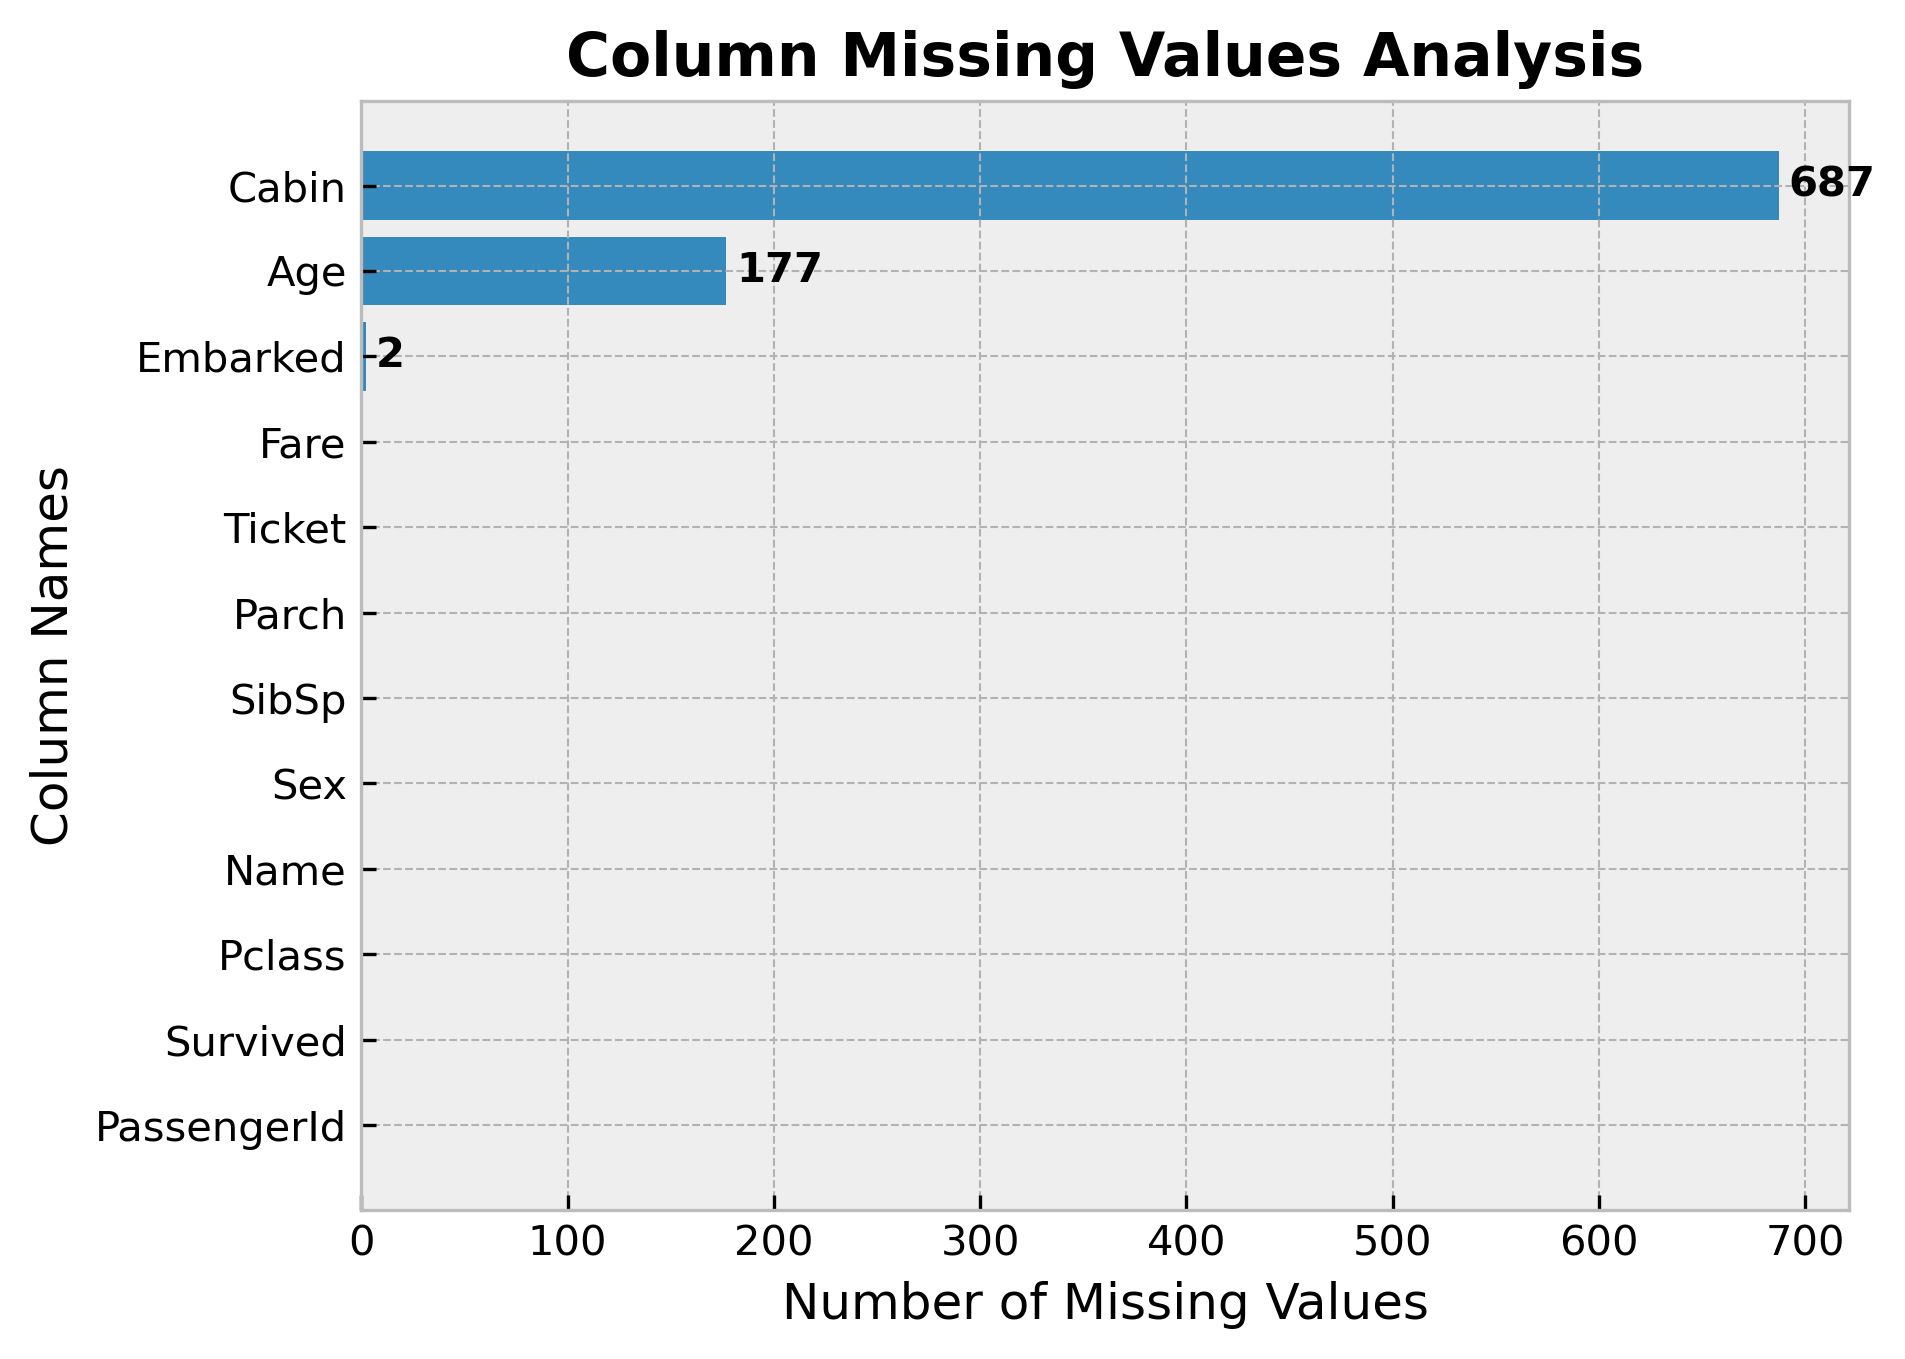

In [254]:
# sort the dataframe
missing_df = missing_df.sort_values('counts')


# change dpi
plt.figure(dpi=300)

# plot graph
plt.barh(missing_df.index, missing_df['counts'])
plt.title('Column Missing Values Analysis', weight='bold')
plt.xlabel('Number of Missing Values')
plt.ylabel('Column Names')


# draw actual counts into text
for i, v in enumerate(missing_df['counts']):
    if v > 0: 
        plt.text(v + 5, i, s=str(v), verticalalignment='center', weight='bold')

plt.show()


It is now clear and we notice `Cabin` column is missing 77.1% of its values and `Age` column is missing 19.87% of its values. 

## Target Value Analysis

Our target value is the `Survived` column. Let's create a **bar and pie** chart to visualize this data.

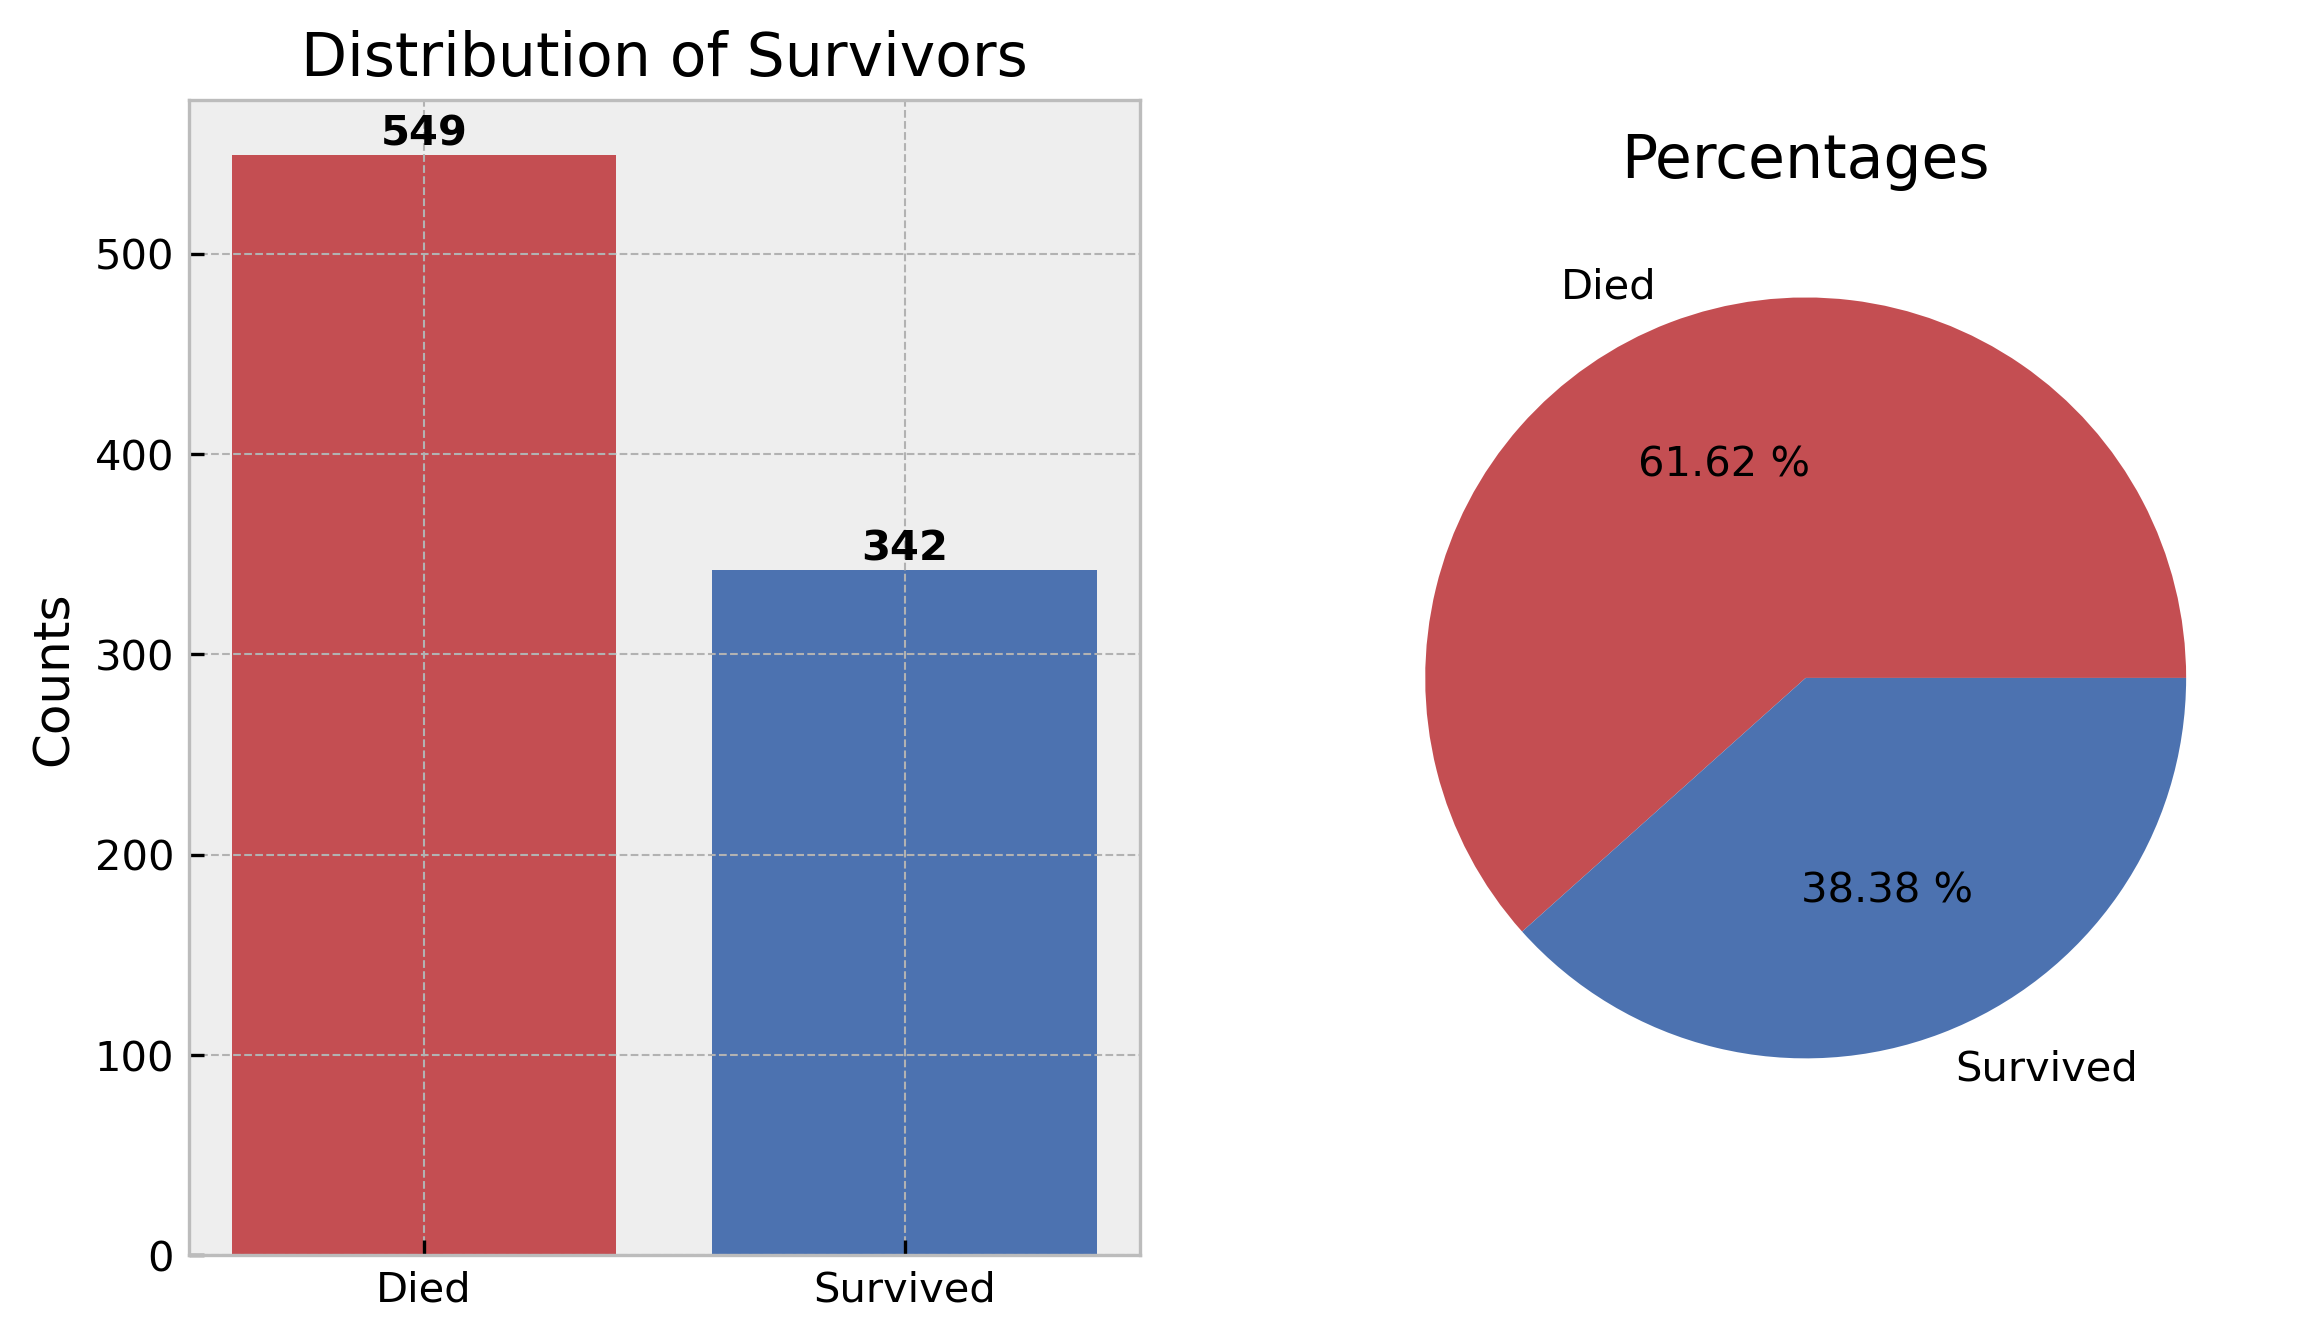

In [255]:
# create subplots
fig, ax = plt.subplots(1,2, figsize=(9,5), dpi=300)

counts = df['Survived'].value_counts()
counts.rename(index={0: 'Died', 1: 'Survived'}, inplace=True)
colors = ['#C44E52', '#4C72B0']

# plot 1: bar graph
ax[0].bar(counts.index, counts.values, color=colors)
ax[0].set_xticks([0, 1])
ax[0].set_ylabel('Counts')
ax[0].set_title('Distribution of Survivors')

## draw text
for i, v in enumerate(counts):
    ax[0].text(i, v + 5, s=str(v), weight='bold', horizontalalignment='center')

# plot 2: pie chart
ax[1].pie(counts.values, labels=counts.index, autopct='%.2f %%', colors=colors)
ax[1].set_title('Percentages')

plt.show()



## Univariate Analysis - Single Variable

**Univariate analysis** involves looking at one single variable at a time. 

The main purpose is to describe and summarise the distribution, central value and spread of each of the data. 

### Numerical Features

In [256]:
# taking a look again at our data types
print(df.dtypes)

# creating a list of numerical columns we want to inspect
num_cols = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']


PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object


In [257]:
# apply value_counts() to inspect the counts of num cols
for col in num_cols:
    print(df[col].value_counts())
    print()

Pclass
3    491
1    216
2    184
Name: count, dtype: int64

Age
24.00    30
22.00    27
18.00    26
19.00    25
28.00    25
         ..
36.50     1
55.50     1
0.92      1
23.50     1
74.00     1
Name: count, Length: 88, dtype: int64

SibSp
0    608
1    209
2     28
4     18
3     16
8      7
5      5
Name: count, dtype: int64

Parch
0    678
1    118
2     80
5      5
3      5
4      4
6      1
Name: count, dtype: int64

Fare
8.0500     43
13.0000    42
7.8958     38
7.7500     34
26.0000    31
           ..
35.0000     1
28.5000     1
6.2375      1
14.0000     1
10.5167     1
Name: count, Length: 248, dtype: int64



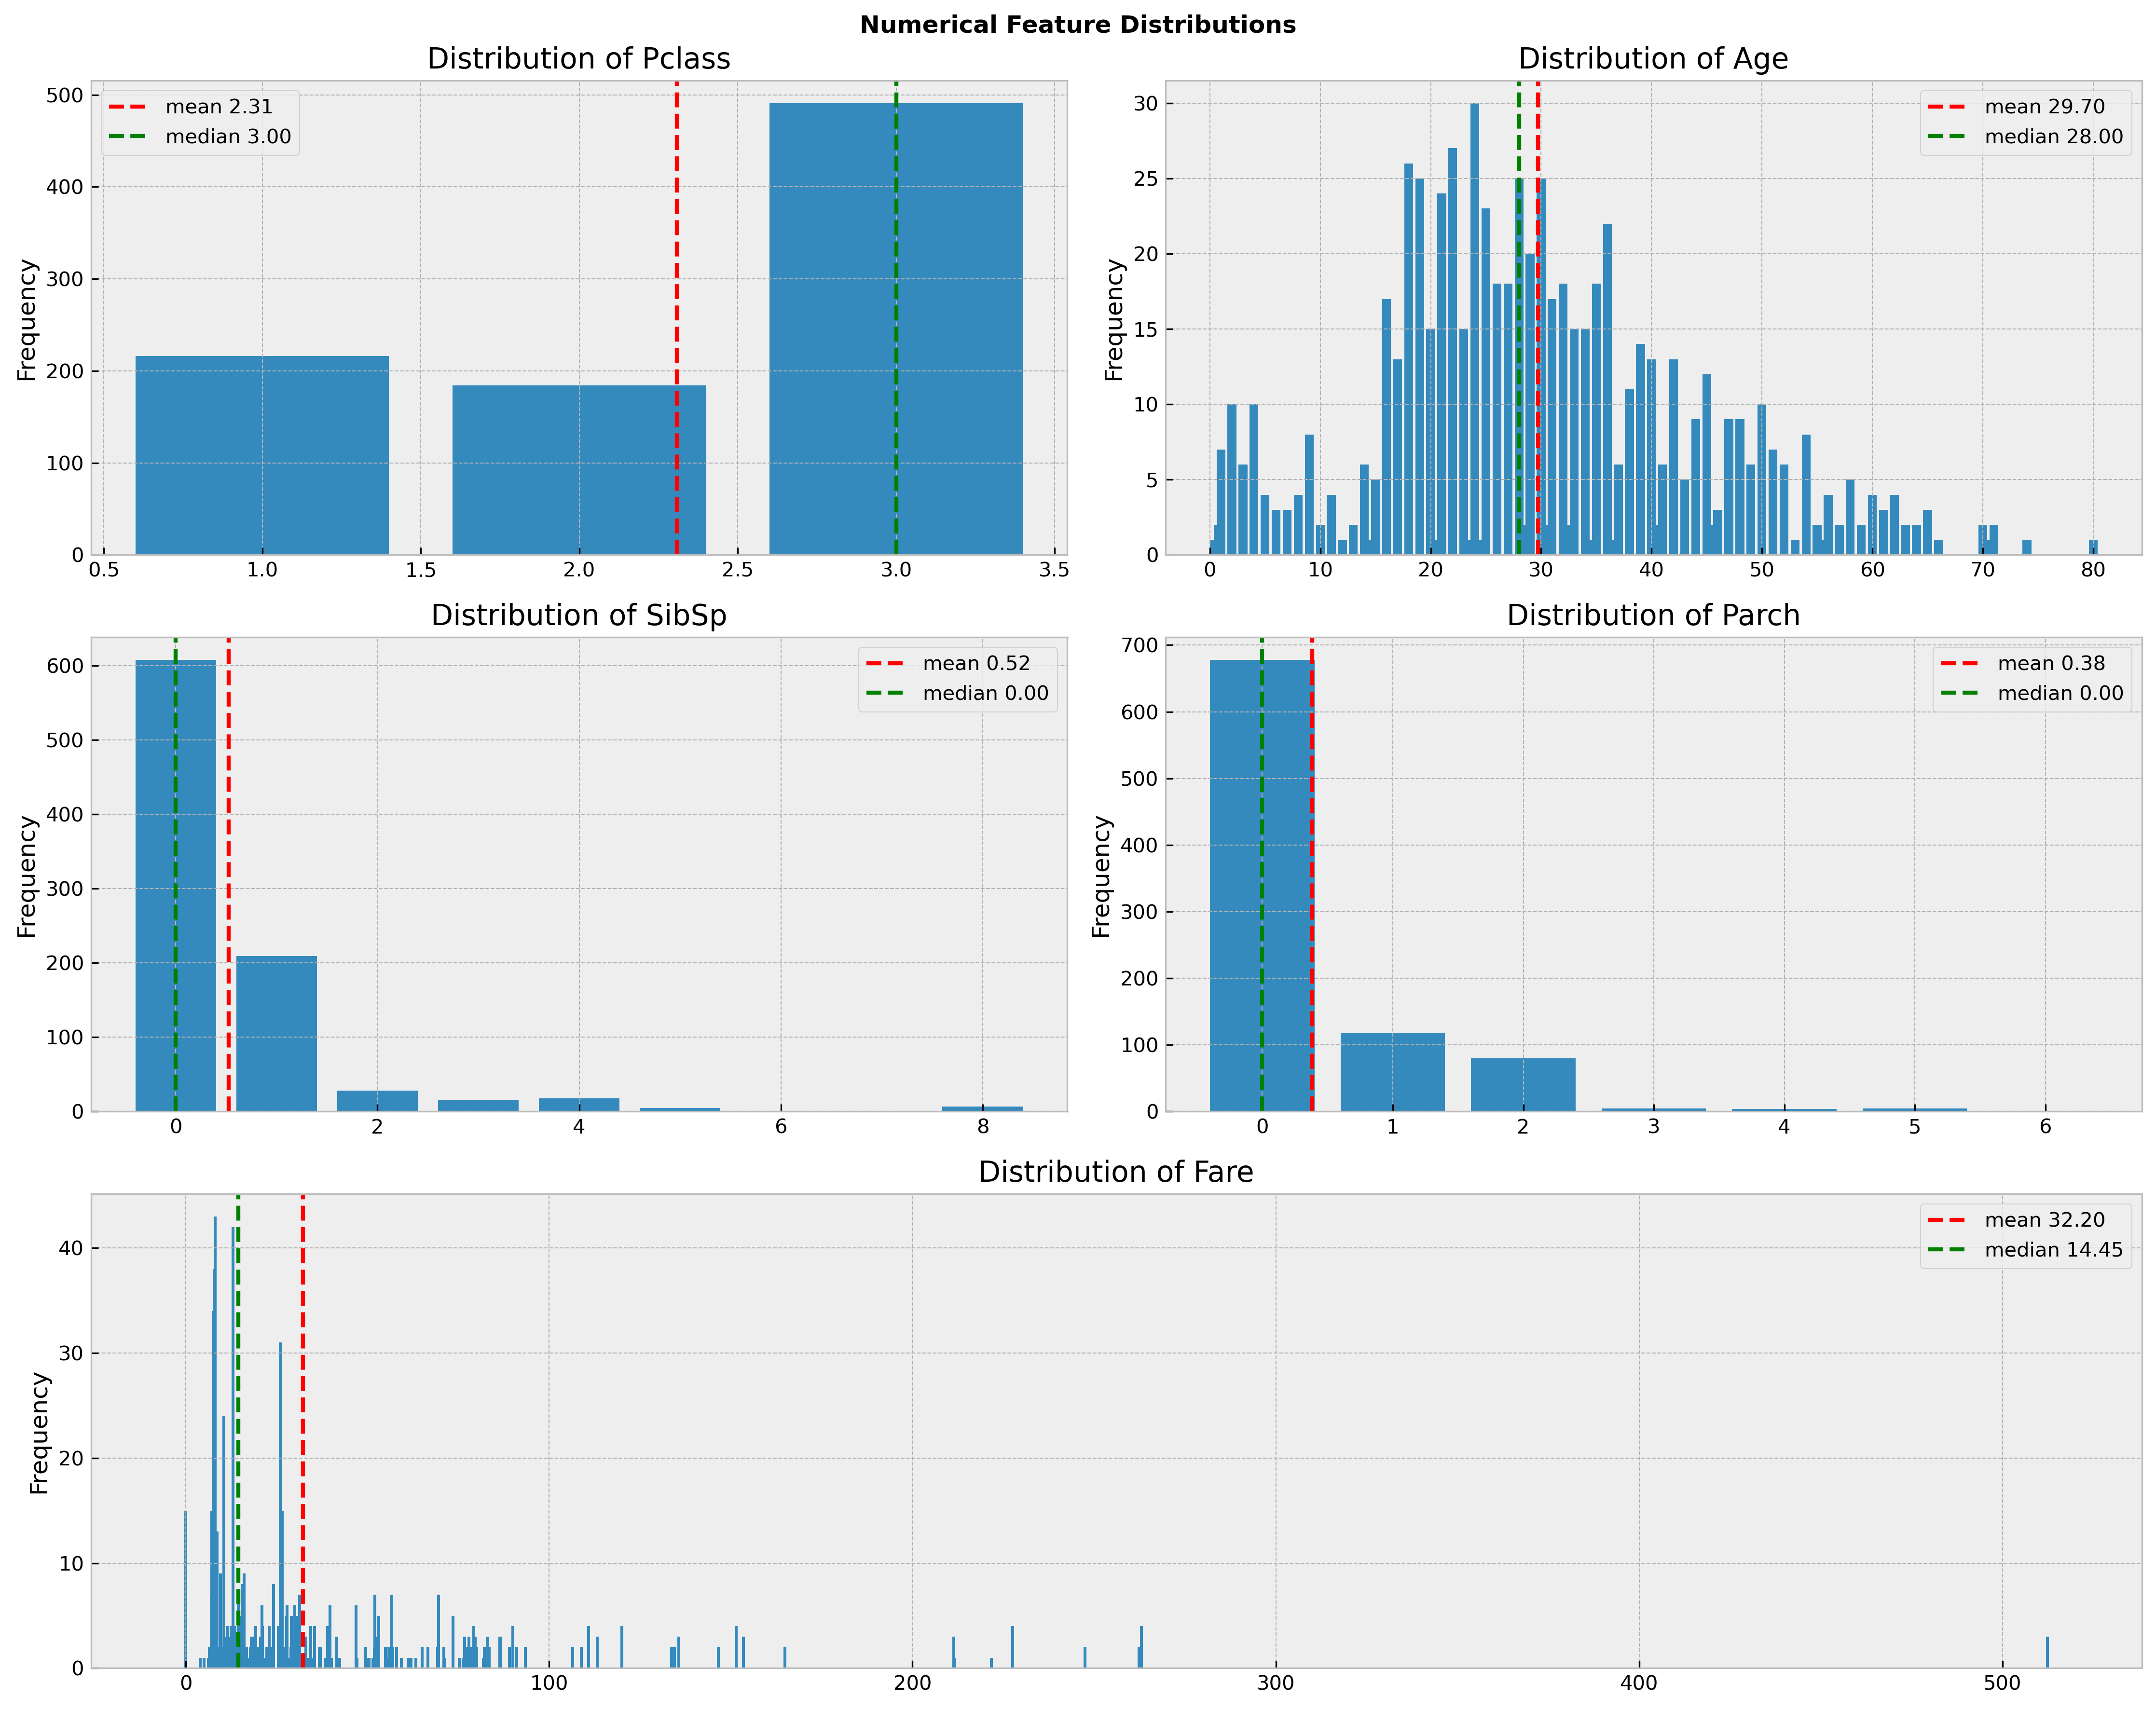

In [258]:
# create layout of plot
layout = [num_cols[0:2],
          num_cols[2:4],
          [num_cols[4]] * 2]

# create subplot
fig, ax = plt.subplot_mosaic(layout, figsize=(15,12), dpi=300)


for col in num_cols: 
    # get frequency of each numerical value 
    values = df[col].value_counts()

    # plot bar graph
    ax[col].bar(values.index, values)
    ax[col].set_title(f'Distribution of {col}')
    ax[col].set_ylabel('Frequency')

    # plot mean and median lines
    mean = df[col].mean()
    med = df[col].median()
    ax[col].axvline(mean, color='red', linestyle='--', label=f'mean {mean:.2f}')
    ax[col].axvline(med, color='green', linestyle='--', label=f'median {med:.2f}')
    ax[col].legend()

plt.suptitle('Numerical Feature Distributions', fontweight='bold')
plt.tight_layout()
plt.show()


`Age` and `Fare` are **continous** variables which the others although are numerical in data type are actually **categorical** variables. 

Hence we apply boxplots on these two variables as there are more meaningful. 

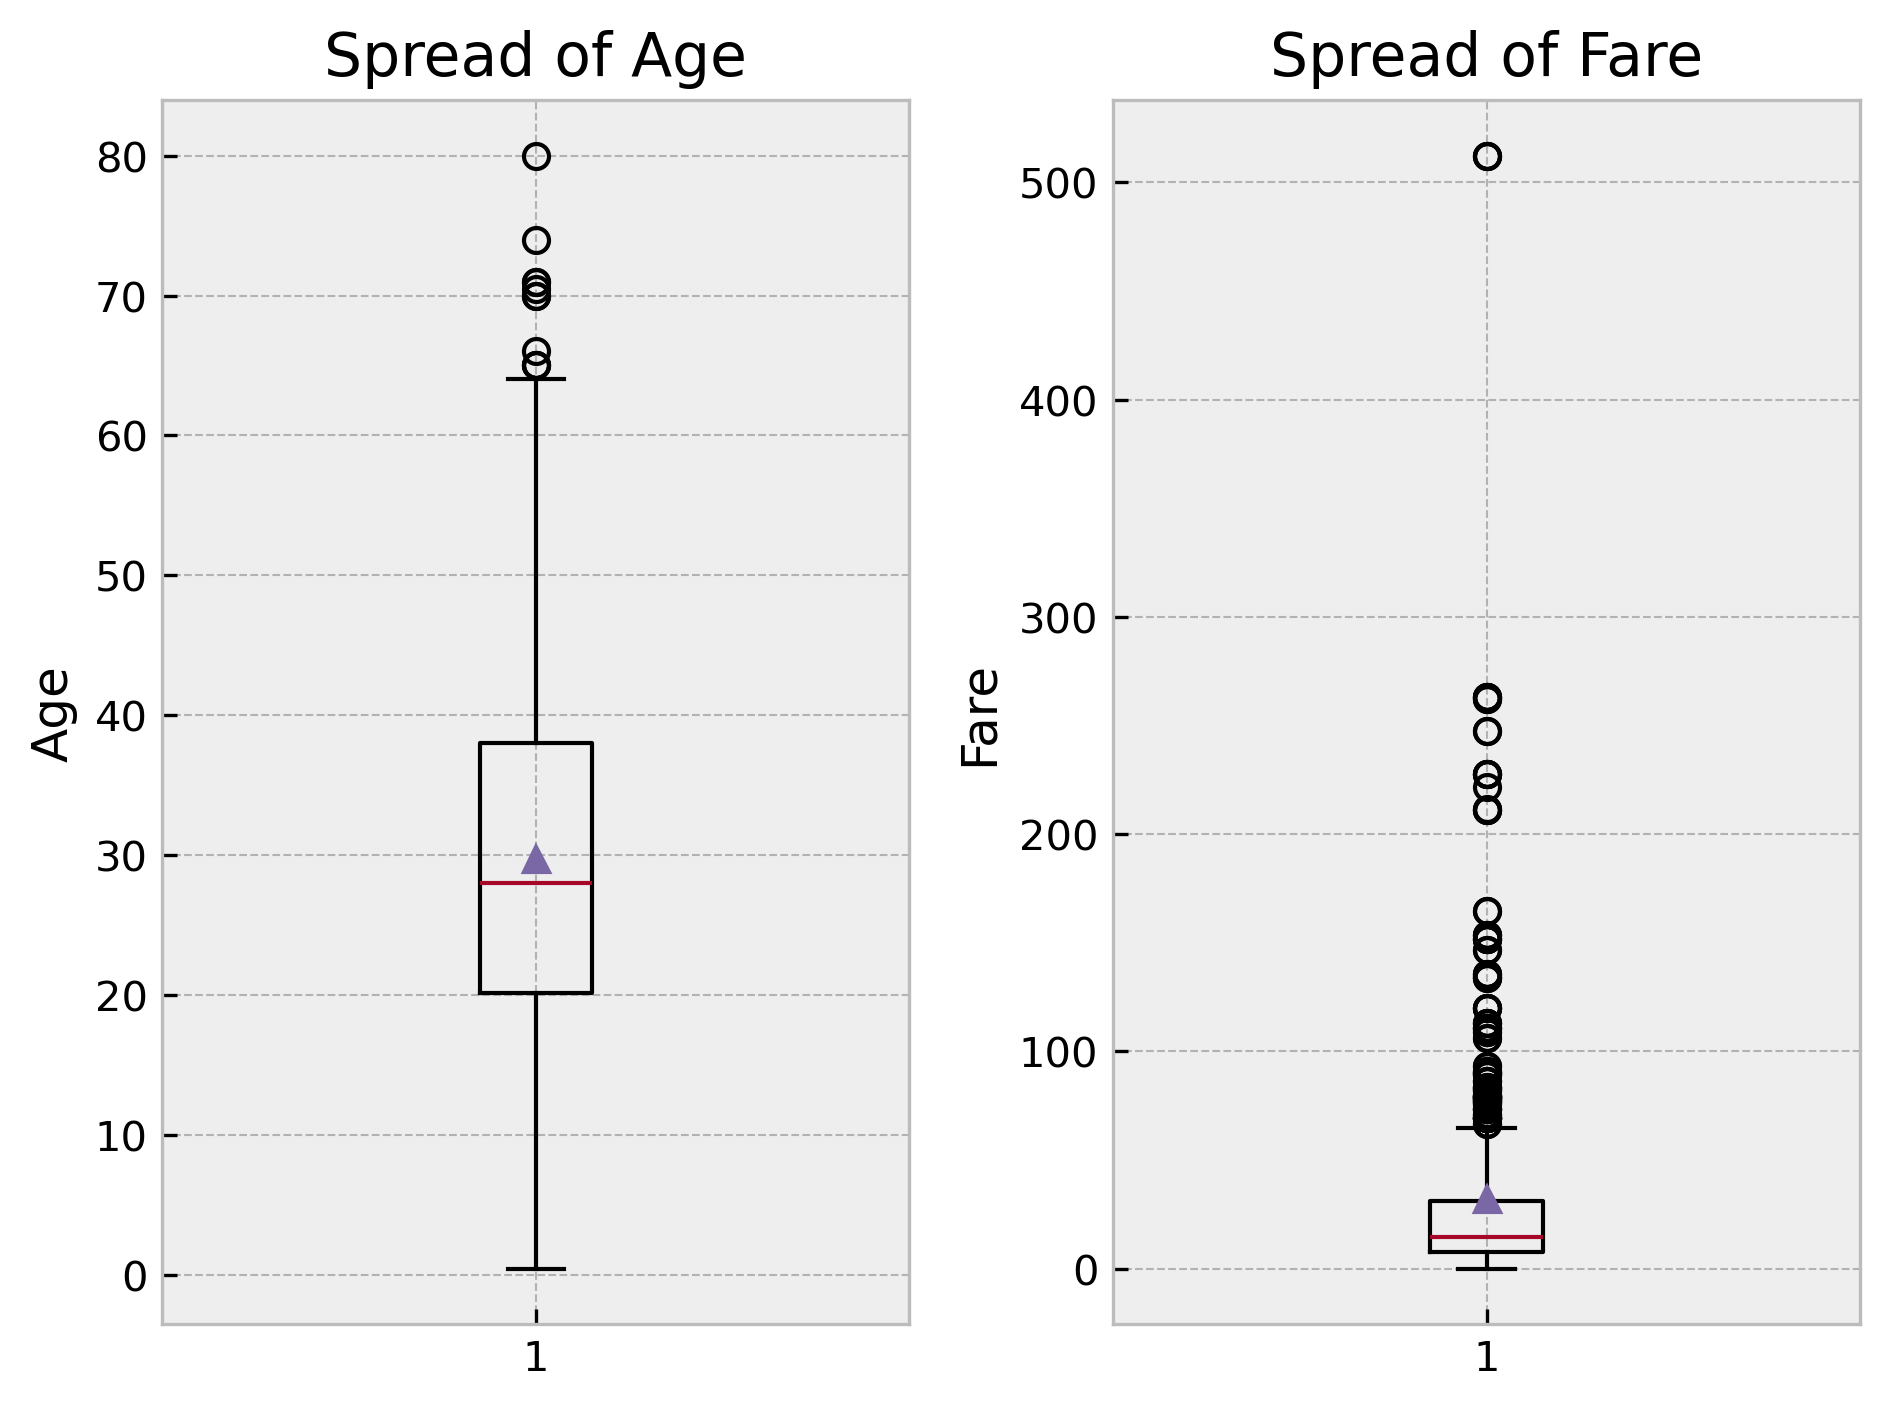

In [259]:
cols = ['Age', 'Fare']

# create subplot
fig, ax = plt.subplots(1,2, dpi=300)

for i, v in enumerate(cols): 
    ax[i].boxplot(df[v].dropna(), showmeans=True)
    ax[i].set_title(f'Spread of {v}')
    ax[i].set_ylabel(v)

plt.tight_layout()
plt.show()


From the distribution plots, we see `Fare` in particular is strongly **right-skewed** as it has a long right tail.

From the boxplots, we notice both variables are **right-skewed** as the mean value sits above the median line likely pulled by the outliers above the top whisker. 

`Fare` in particular demonstrates a stronger skew and conclusions from both distribution and boxplots are consistent. 

### Categorical Features

Now let's analyse our categorical variables by creating visualizations to show frequency distributions. 

We drop the `Cabin` columns due to a high number of missing values. Additionally, we also drop `Name` and `Ticket` columns as we will perform analysis on these features individually. 

In [260]:
# get columns where data type is object 
cat_cols = df.select_dtypes(include='object').columns

# drop 'Cabin' and 'Name' column
cat_cols = cat_cols.drop(['Name', 'Cabin', 'Ticket'])

# convert to list
cat_cols = list(cat_cols)
cat_cols

['Sex', 'Embarked']

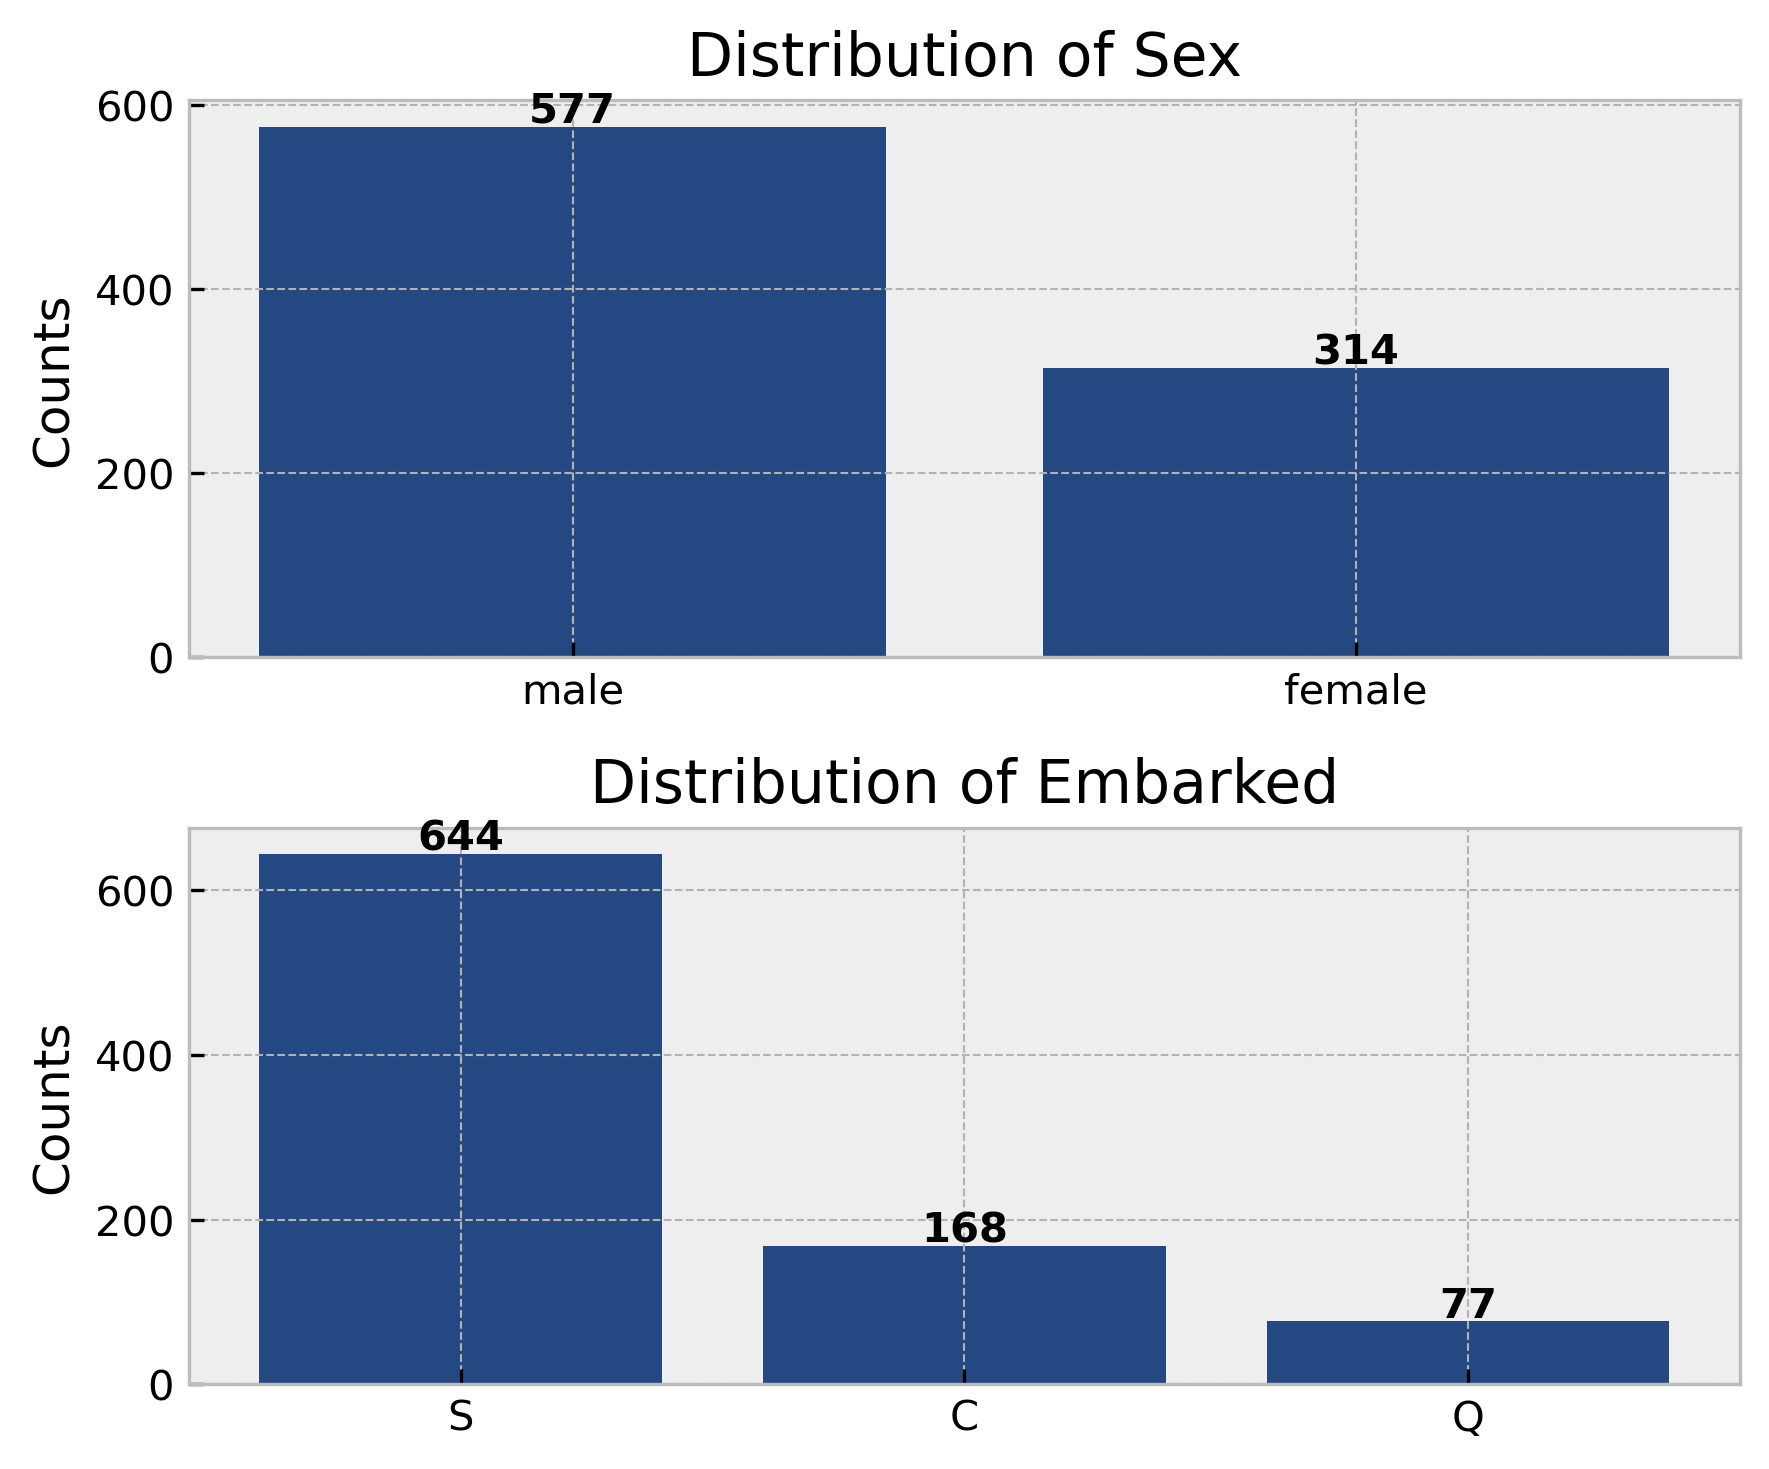

In [261]:
# create subplots
fig, ax = plt.subplots(2,1, figsize=(6,5), dpi=300)

for i, v in enumerate(cat_cols):
    # get value counts of each feature
    values = df[v].value_counts()

    # plot bar graph
    ax[i].bar(values.index, values, color='#234882')
    ax[i].set_ylabel('Counts')
    ax[i].set_title(f'Distribution of {v}')

    # plot actual values
    for i2, v2 in enumerate(values):
        ax[i].text(i2, v2 + 5, s=str(v2), weight='bold', ha='center')

plt.tight_layout()
plt.show()

Now let's take a look at the `Ticket` feature. The best way to analyze a column we are unsure about is to run **value_counts()**.

We notice that the same ticket was given to multiple people, since we have columns `Parch` and `SibSp` this could imply family members were given the same ticket. 

In [262]:
with pd.option_context('display.max_rows', None): # allow all rows to be displayed
    # value counts
    print(df['Ticket'].value_counts().sort_index())

    # check min and max
    print(f'\nmin num of ticket: {df['Ticket'].value_counts().min()}')
    print(f'max num of ticket: {df['Ticket'].value_counts().max()}')




Ticket
110152                3
110413                3
110465                2
110564                1
110813                1
111240                1
111320                1
111361                2
111369                1
111426                1
111427                1
111428                1
112050                1
112052                1
112053                1
112058                1
112059                1
112277                1
112379                1
113028                1
113043                1
113050                1
113051                1
113055                1
113056                1
113059                1
113501                1
113503                1
113505                2
113509                1
113510                1
113514                1
113572                2
113760                4
113767                1
113773                1
113776                2
113781                4
113783                1
113784                1
113786                1
113787   

Now let's inspect the `Name` column. 

The the sample of names below, we notice names follow a consistent format: **Surname, Title. Given Names**. 

We can split the names to obtain the titles of the passengers, titles can act as a proxy for the social class of passengers which have the potential to carry information. 


In [263]:
# check a sample of 15 names
df['Name'].sample(15)

872                             Carlsson, Mr. Frans Olof
796                          Leader, Dr. Alice (Farnham)
318                             Wick, Miss. Mary Natalie
792                              Sage, Miss. Stella Anna
89                                Celotti, Mr. Francesco
547                           Padro y Manent, Mr. Julian
438                                    Fortune, Mr. Mark
49         Arnold-Franchi, Mrs. Josef (Josefine Franchi)
799    Van Impe, Mrs. Jean Baptiste (Rosalie Paula Go...
449                       Peuchen, Major. Arthur Godfrey
258                                     Ward, Miss. Anna
529                          Hocking, Mr. Richard George
597                                  Johnson, Mr. Alfred
0                                Braund, Mr. Owen Harris
94                                     Coxon, Mr. Daniel
Name: Name, dtype: object

In [264]:
# split the string by ','
title = df['Name'].str.split(',', expand=True)

# then split by '.'
title = title[1].str.split('.', expand=True)

# extract the first (title) column
title = title[0]
title

0         Mr
1        Mrs
2       Miss
3        Mrs
4         Mr
       ...  
886      Rev
887     Miss
888     Miss
889       Mr
890       Mr
Name: 0, Length: 891, dtype: object

In [265]:
# run value counts and normalize it
title.value_counts(normalize=True)

0
Mr              0.580247
Miss            0.204265
Mrs             0.140292
Master          0.044893
Dr              0.007856
Rev             0.006734
Mlle            0.002245
Major           0.002245
Col             0.002245
the Countess    0.001122
Capt            0.001122
Ms              0.001122
Sir             0.001122
Lady            0.001122
Mme             0.001122
Don             0.001122
Jonkheer        0.001122
Name: proportion, dtype: float64

Using **value_counts** we identify:
* 'Mr' (Majority, 58%)
* 'Miss' (20%) and 'Mrs' (14%)
* 'Master' (4%)
* Others (< 1% each)

## Bivariate Analysis - Comparing Features to Target Features

Having complete a univariate analysis of analyzing each variable independently. We can drawing comparisons between how each variable relates to the target variable `Survived`.

We start by looking at survival rates of categorical columns. 

In [266]:
# new cat_cols
cat_cols = ['Pclass', 'SibSp', 'Parch', 'Sex', 'Embarked']

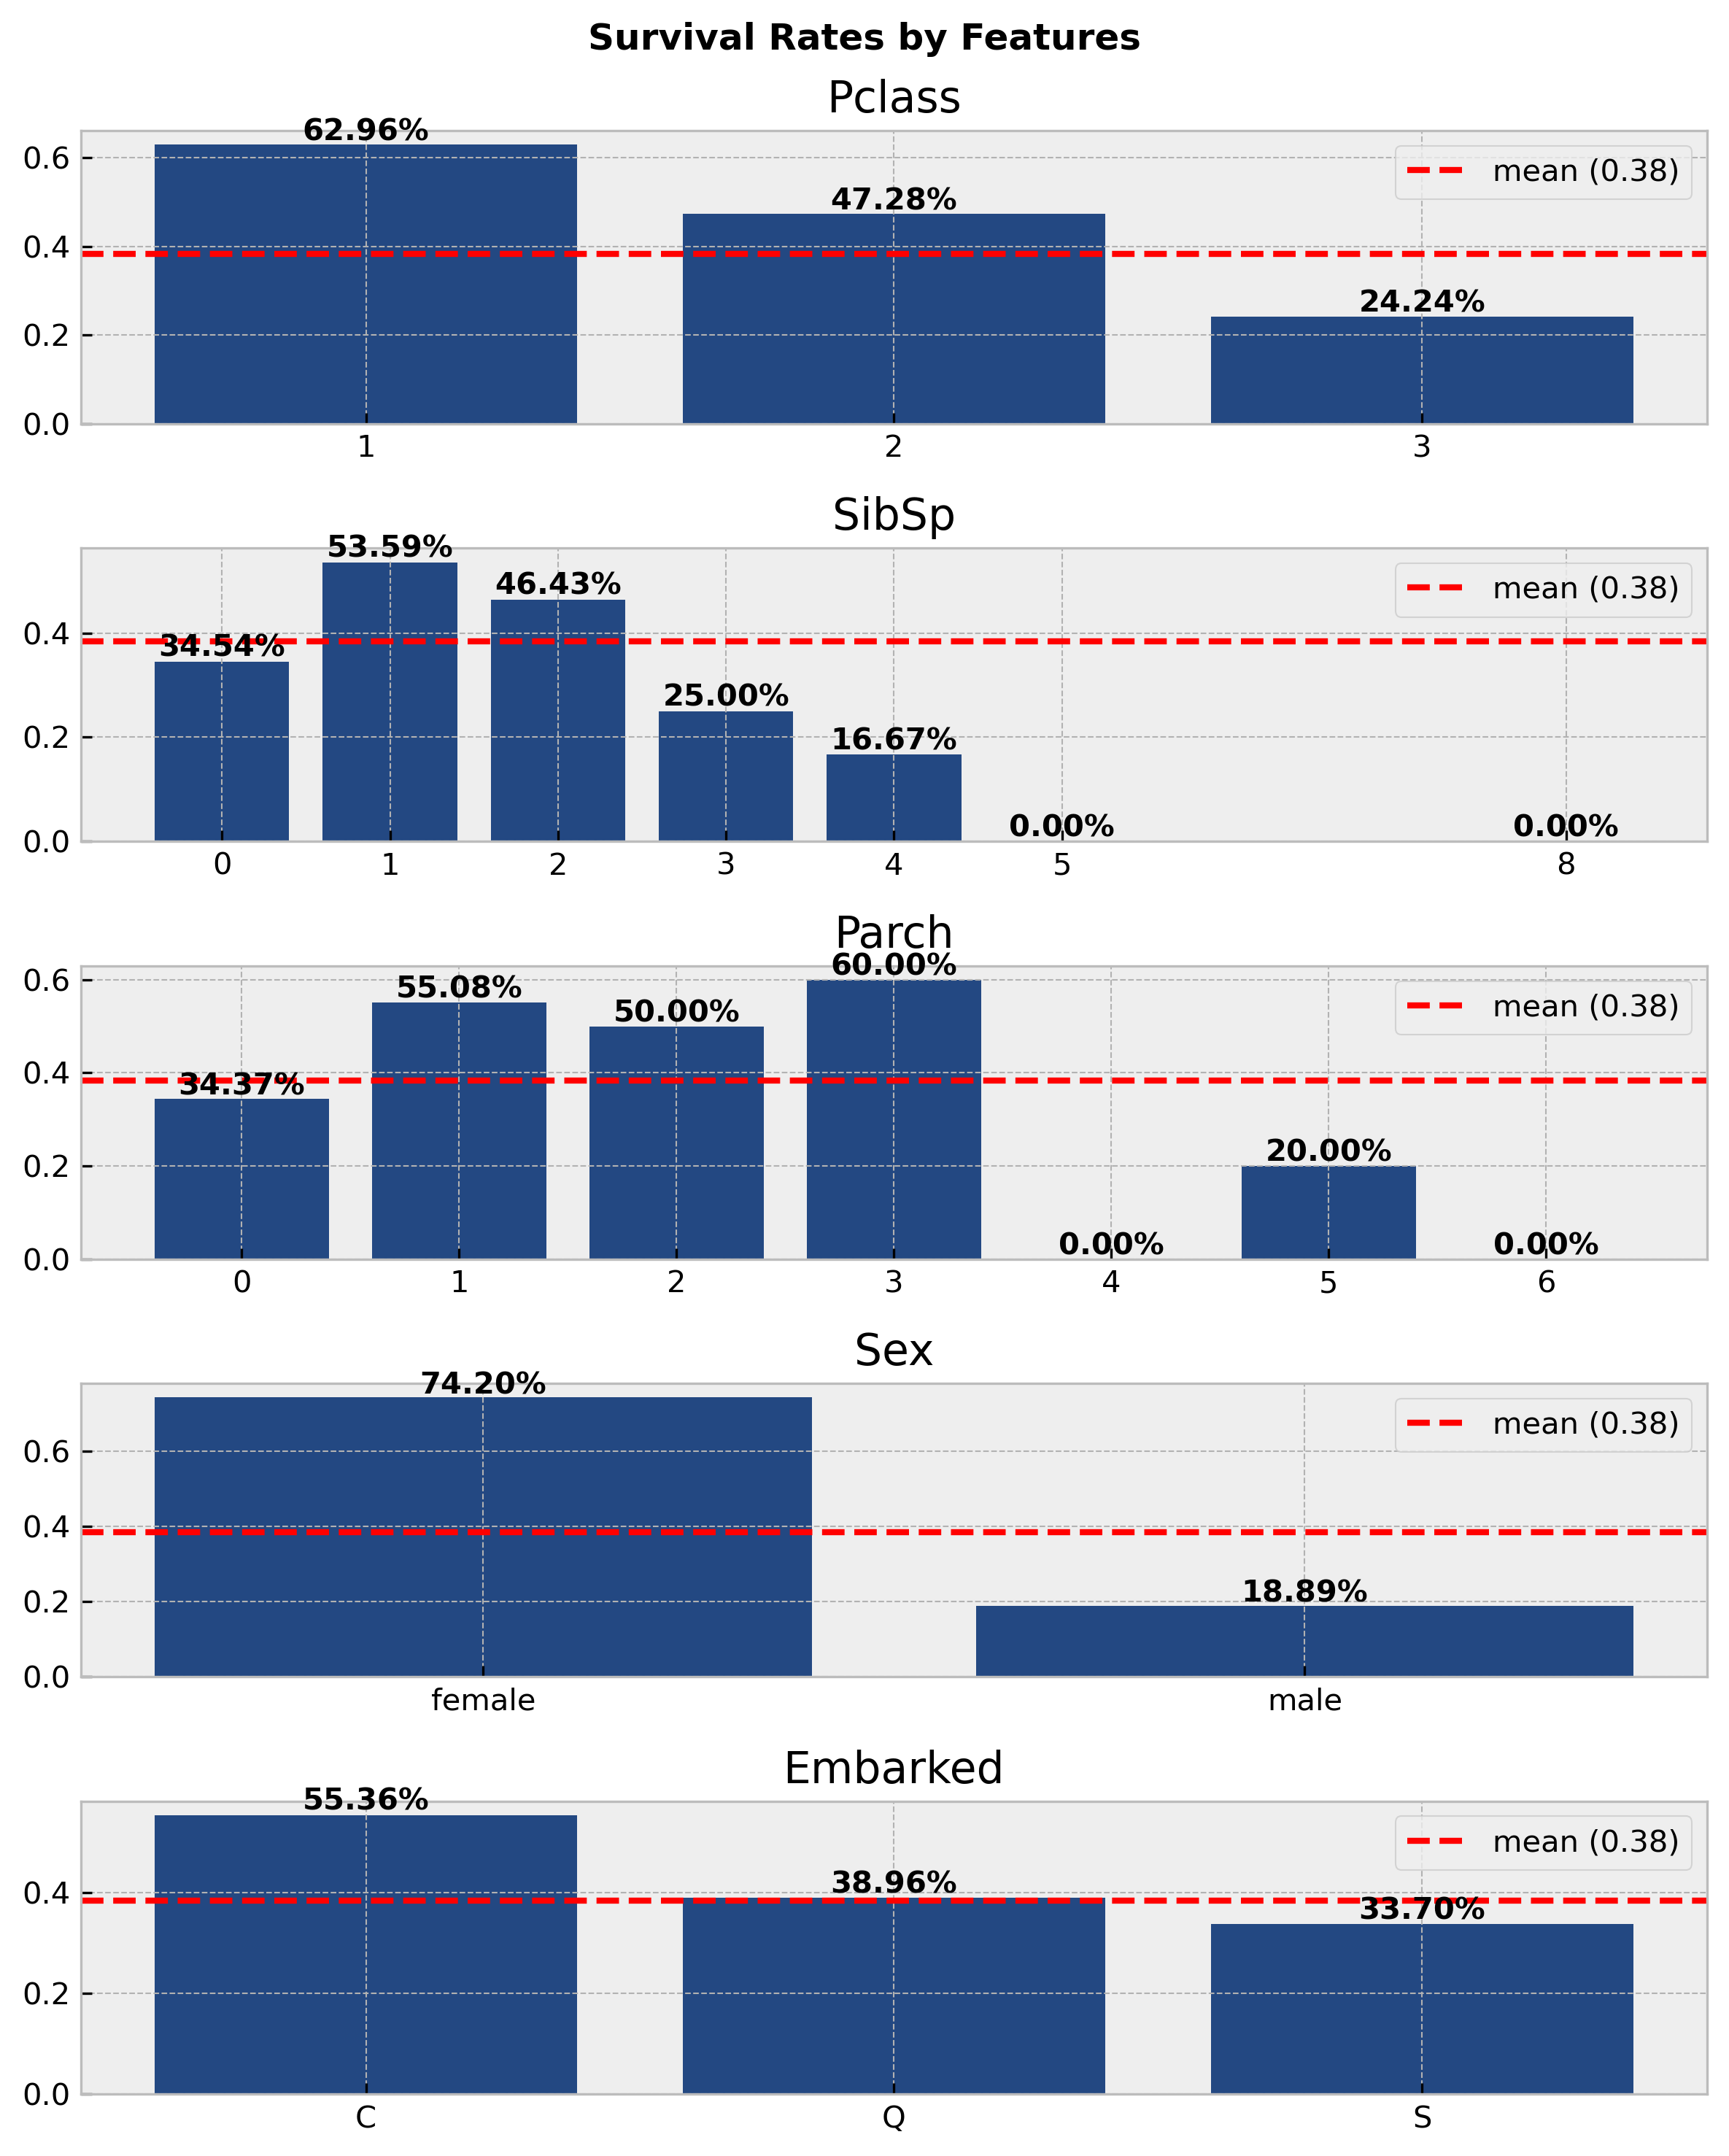

In [267]:
# create subplot
fig, ax = plt.subplots(5,1, figsize=(8, 10), dpi=300)

for i, v in enumerate(cat_cols):
    # calculate survival rates
    survival_rates = df.groupby([v])['Survived'].mean()

    # create plots
    ax[i].bar(survival_rates.index, survival_rates, color='#234882')
    ax[i].set_title(v)
    ax[i].set_xticks(survival_rates.index)

    # draw values 
    for label, val in survival_rates.items():
        ax[i].text(label, val + 0.01, s=f'{(val * 100):.2f}%', ha='center', weight='bold')

    # draw mean and median lines
    mean = df['Survived'].mean()
    ax[i].axhline(mean, color='red', linestyle='--', label=f'mean ({mean:.2f})')
    ax[i].legend()
    

plt.suptitle('Survival Rates by Features', weight='bold')
plt.tight_layout()
plt.show()




We can also compare survival rates grouped by `Sex` and `Pclass`.

In [268]:
# obtaining survial rates
sur_rates_grp = df.groupby(['Sex', 'Pclass'])['Survived'].mean()
sur_rates_grp

Sex     Pclass
female  1         0.968085
        2         0.921053
        3         0.500000
male    1         0.368852
        2         0.157407
        3         0.135447
Name: Survived, dtype: float64

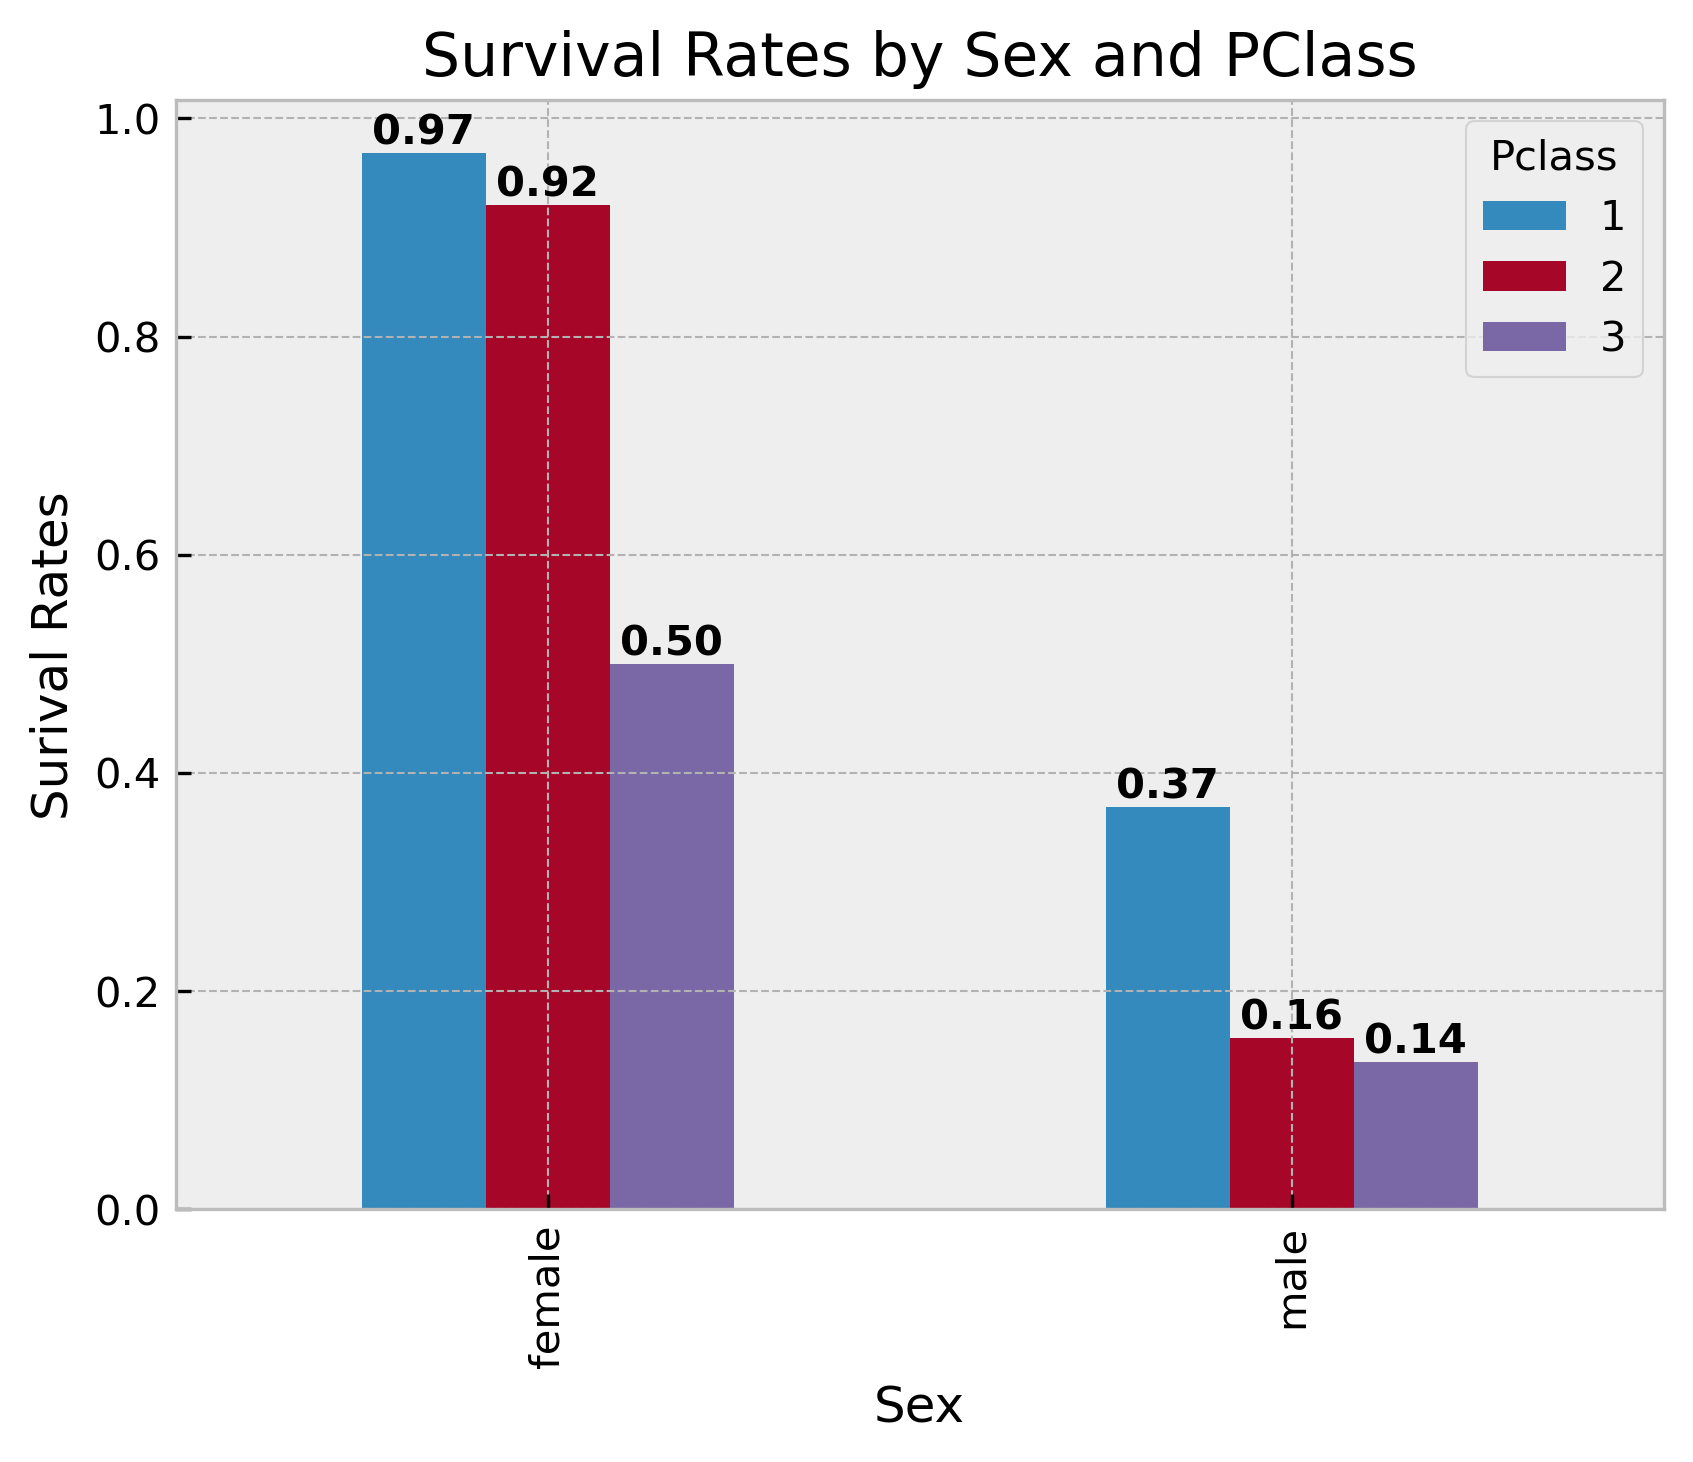

In [269]:
# plotting
fig, ax = plt.subplots(dpi=300)

sur_rates_grp.unstack().plot(kind='bar', ax=ax)
for c in ax.containers:
    ax.bar_label(c, fmt='%.2f', weight='bold')

plt.title('Survival Rates by Sex and PClass')
plt.ylabel('Surival Rates')

plt.show()


We can now examine the age distribution with survival. 

We implement a histogram and kde plot

1      38.0
2      26.0
3      35.0
8      27.0
9      14.0
       ... 
875    15.0
879    56.0
880    25.0
887    19.0
889    26.0
Name: Age, Length: 290, dtype: float64


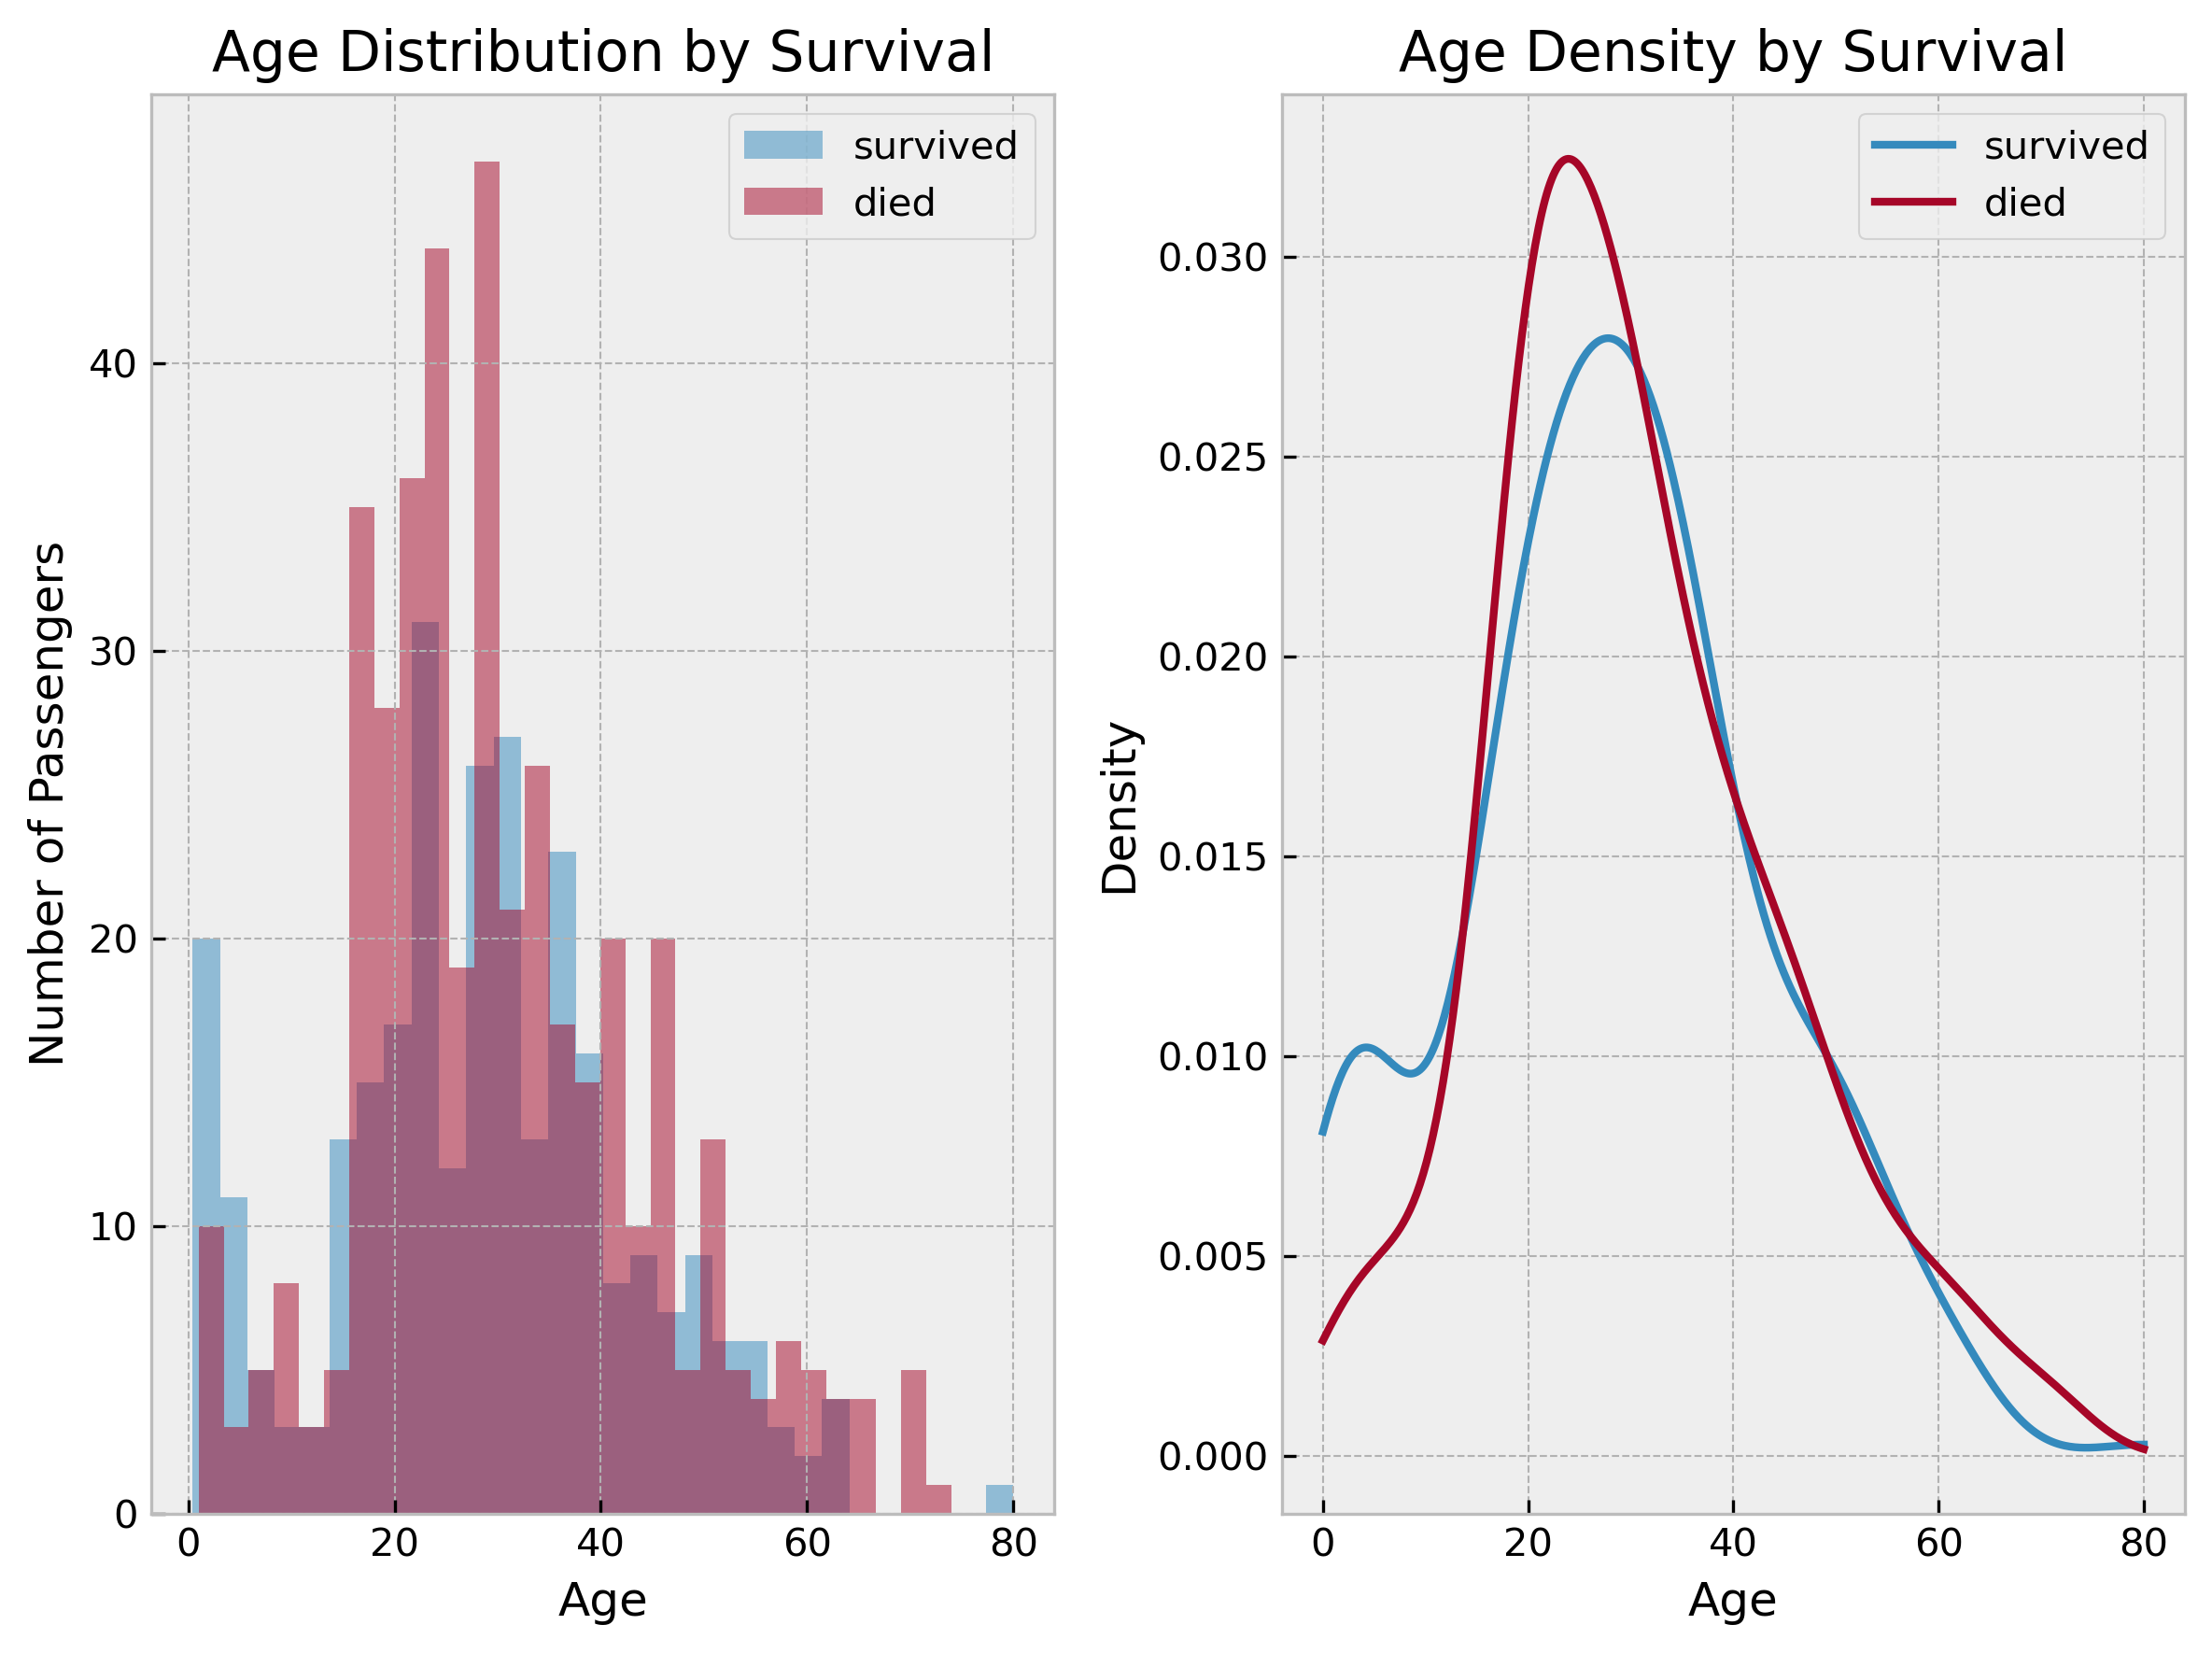

In [270]:
# get df of ages for passengers that survived and died
survived_age = df[df['Survived'] == 1]['Age'].dropna()
died_age = df[df['Survived'] == 0]['Age'].dropna()
print(survived_age)

# plotting
fig, ax = plt.subplots(1,2, figsize=(8,6), dpi=300)

## plot 1: histogram of age distribution with survival
ax[0].hist(survived_age, bins=30, alpha=0.5, label='survived')
ax[0].hist(died_age, bins=30, alpha=0.5, label='died')
ax[0].set_title('Age Distribution by Survival')
ax[0].set_ylabel('Number of Passengers')
ax[0].set_xlabel('Age')
ax[0].legend()

## plot 2: kernal density estimate (KDE) plot
x = np.linspace(0, 80, 500)
survived_age.plot.kde(ax=ax[1], ind=x, label='survived')
died_age.plot.kde(ax=ax[1], ind=x, label='died')
ax[1].set_title('Age Density by Survival')
ax[1].set_xlabel('Age')
ax[1].set_ylabel('Density')
ax[1].legend()

plt.tight_layout()
plt.show()


Examining average fare for those that survived and died. 

/var/folders/8j/5y8s8l5j7qnc7bjs1pssrnb40000gn/T/ipykernel_3825/3633393084.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([survived_fares, died_fares], labels=labels, showmeans=True)


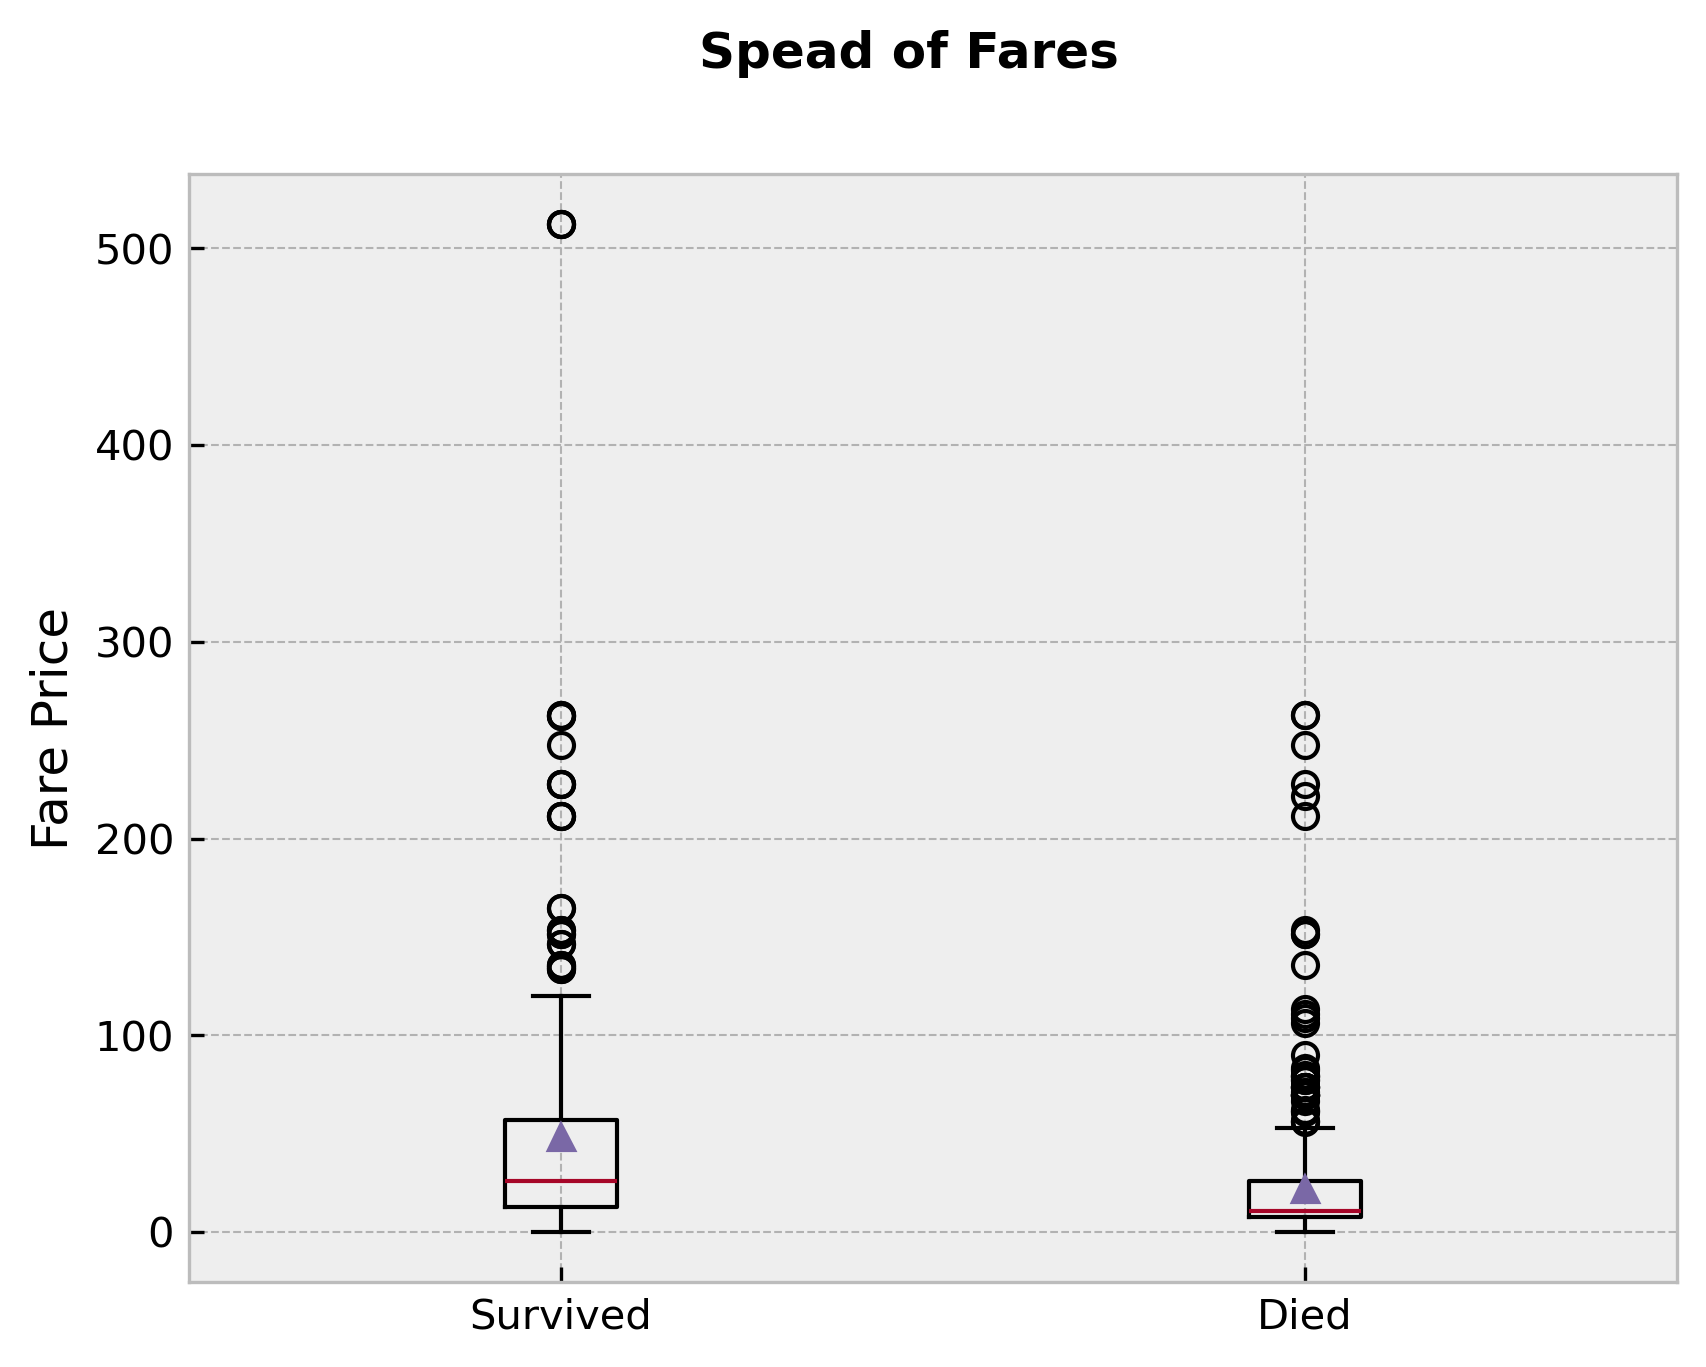

Average fare (Survived): $48.40
Median fare (Survived): $26.00

Average fare (Died): $22.12
Median fare (Died): $10.50


In [271]:
# get df of fares for passengers that survived and died
survived_fares = df[df['Survived'] == 1]['Fare']
died_fares = df[df['Survived'] == 0]['Fare']
labels = ['Survived', 'Died']

# create subplots
fig, ax = plt.subplots(dpi=300)

## plot 1: boxplot of fares for survived
ax.boxplot([survived_fares, died_fares], labels=labels, showmeans=True)
ax.set_ylabel('Fare Price')

plt.suptitle('Spead of Fares', weight='bold')
plt.show()

# calculate mean and median fares
print(f'Average fare (Survived): ${survived_fares.mean():.2f}')
print(f'Median fare (Survived): ${survived_fares.median():.2f}\n')
print(f'Average fare (Died): ${died_fares.mean():.2f}')
print(f'Median fare (Died): ${died_fares.median():.2f}')


Examining `SibSp` (Number sibling and spouse) and `Parch` (Number parent and child) with survival.

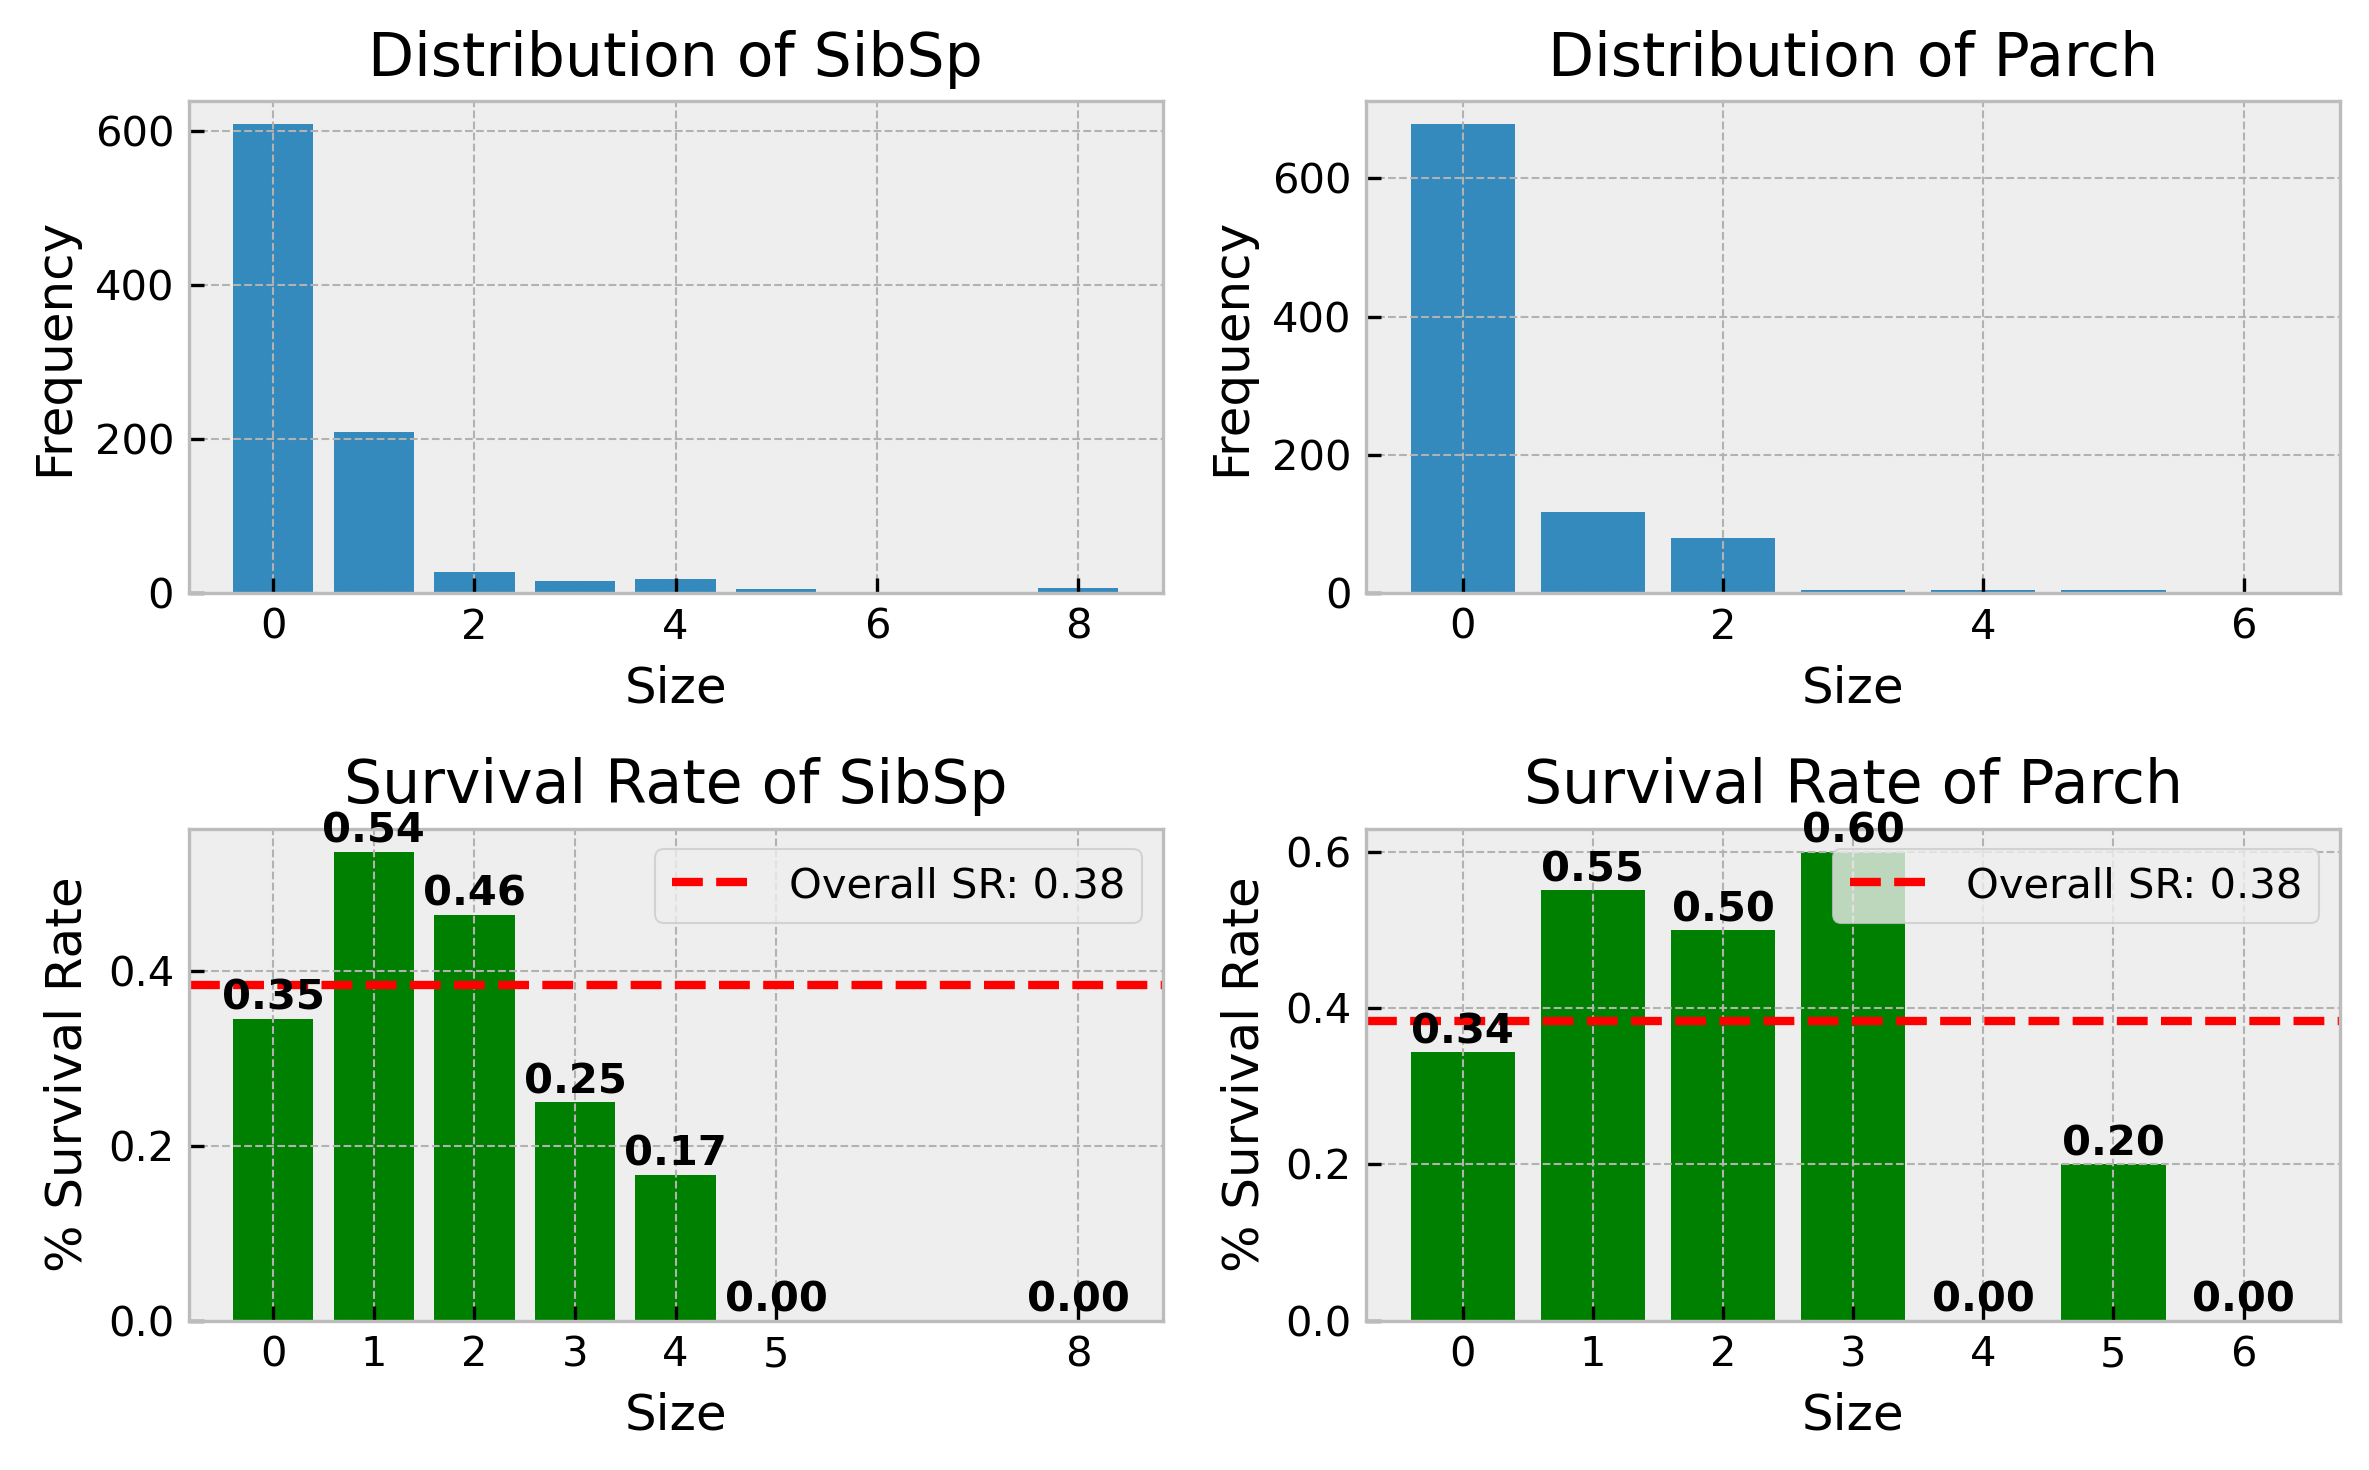

In [272]:
cols = ['SibSp', 'Parch']

# plotting 
fig, ax = plt.subplots(2,2, dpi=300, figsize=(8, 5))
ax = ax.flatten()

overall_sr = df['Survived'].mean()

for i, v in enumerate(cols):
    # plots 1 & 2: dist of SibSp and Parch
    values = df[v].value_counts()
    ax[i].bar(values.index, values)
    ax[i].set_title(f'Distribution of {v}')
    ax[i].set_ylabel('Frequency')
    ax[i].set_xlabel('Size')

    # plots 3 & 4: survival rate of SibSp and Parch
    survival = df.groupby(v)['Survived'].mean()
    bars = ax[i + 2].bar(survival.index, survival, color='green')
    ax[i + 2].set_title(f'Survival Rate of {v}')
    ax[i + 2].axhline(overall_sr, linestyle='--', color='red', label=f'Overall SR: {overall_sr:.2f}')
    ax[i + 2].set_xlabel('Size')
    ax[i + 2].set_ylabel('% Survival Rate')
    ax[i + 2].set_xticks(survival.index)
    ax[i + 2].legend(loc='upper right')
    ax[i + 2].bar_label(bars, fmt='%.2f', weight='bold')


plt.tight_layout()
plt.show()


We can also combine `SibSp` and `Parch` to create a new feature `familysize` and attempt to examine this variable against survival rates. 

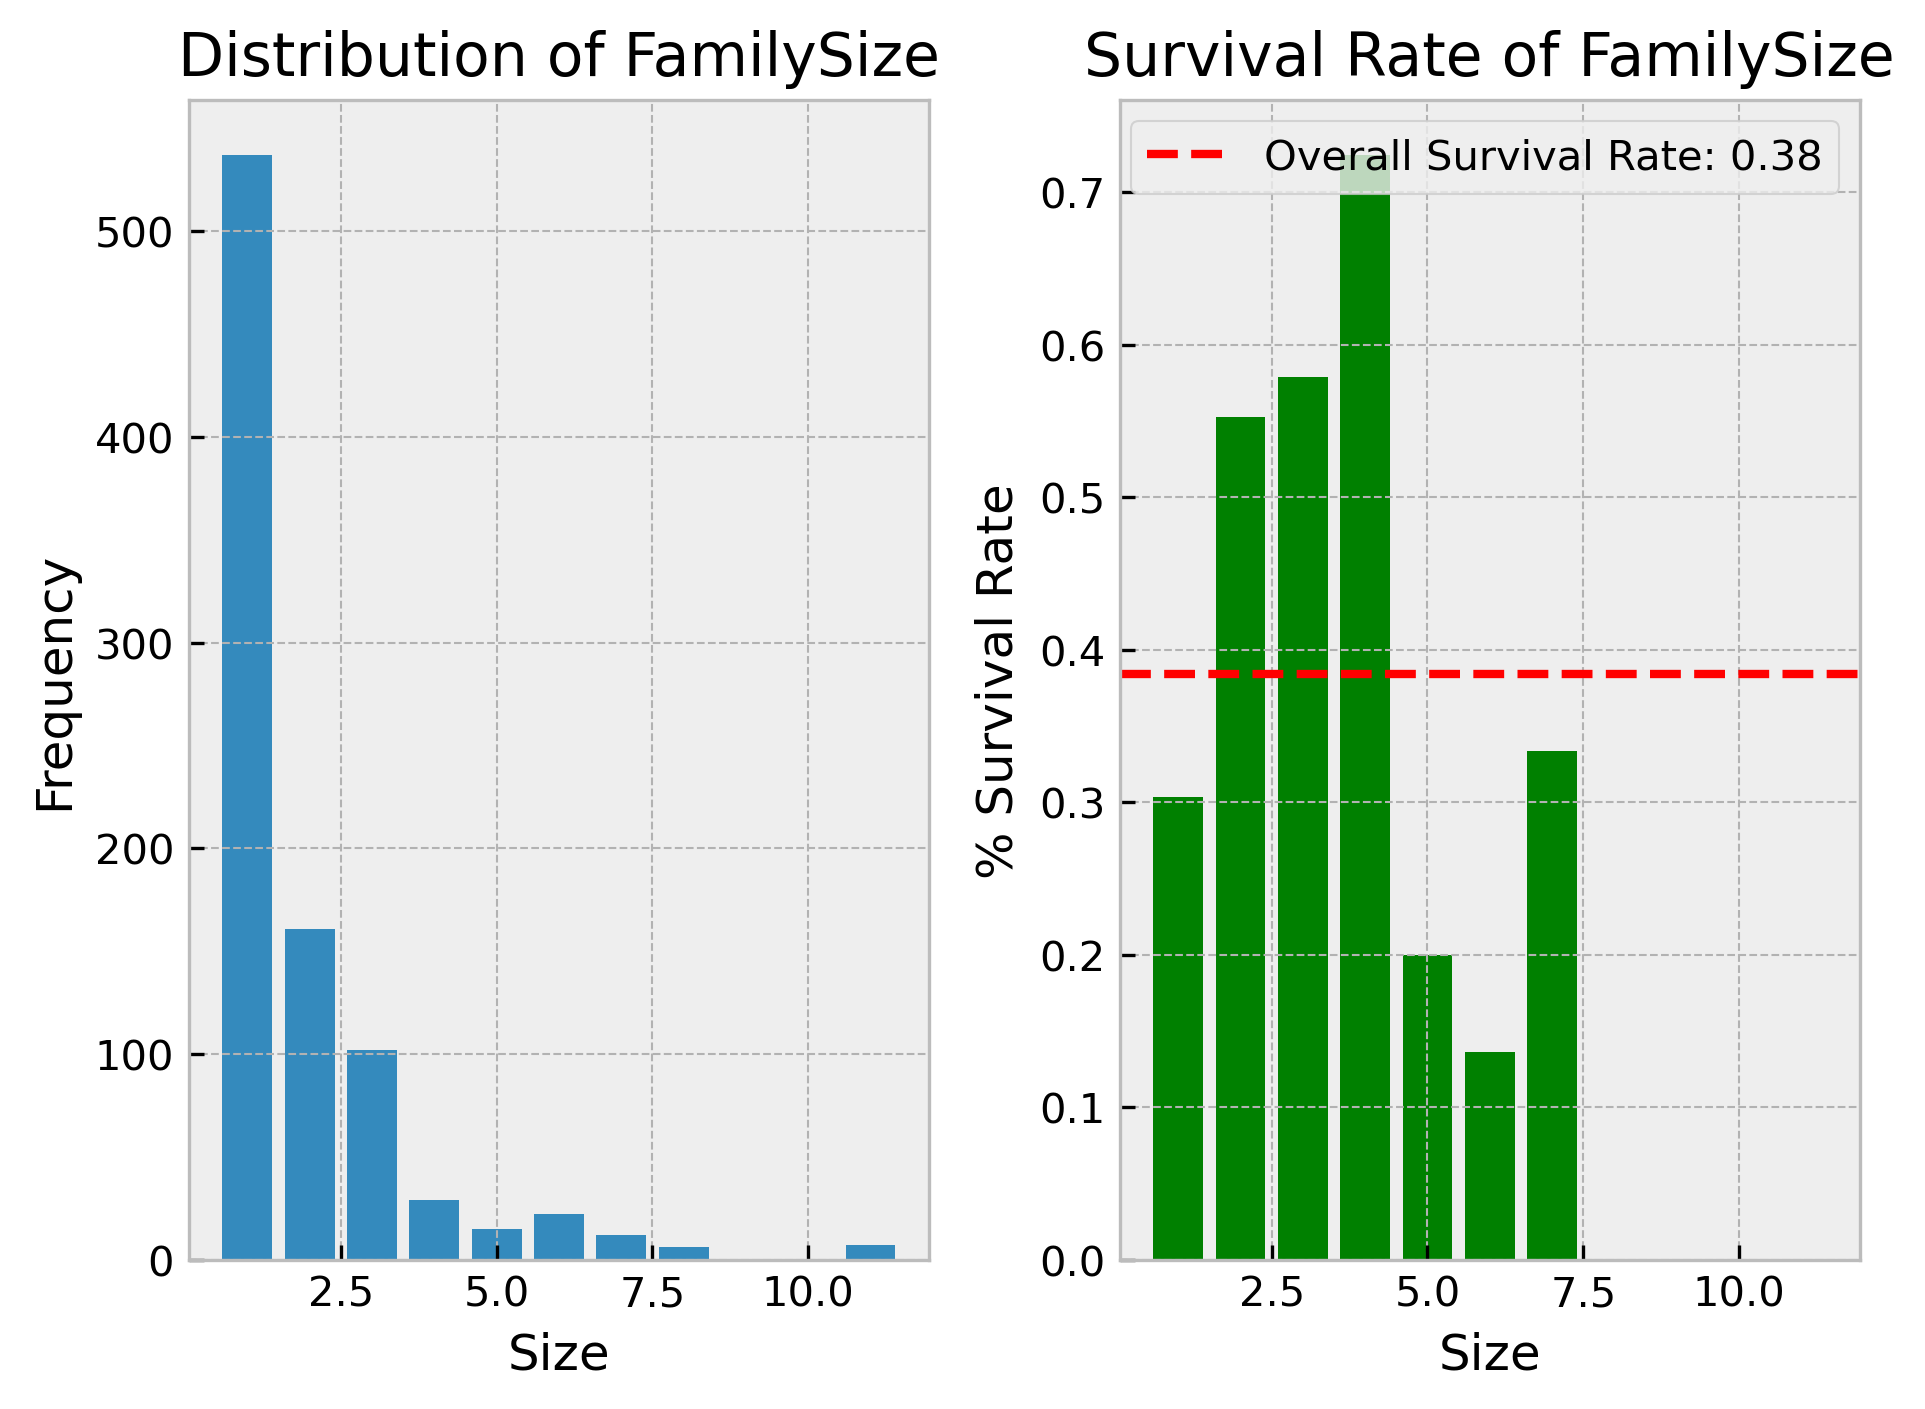

In [273]:
# create new variable 'familysize'
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1

# plotting 
fig, ax = plt.subplots(1,2, dpi=300)

# plots 1: dist of 'FamilySize'
values = df['FamilySize'].value_counts()
ax[0].bar(values.index, values)
ax[0].set_title('Distribution of FamilySize')
ax[0].set_ylabel('Frequency')
ax[0].set_xlabel('Size')

# plots 2: survival rate of 'FamilySize'
survival = df.groupby(['FamilySize'])['Survived'].mean()
ax[1].bar(survival.index, survival, color='green')
ax[1].set_title('Survival Rate of FamilySize')
ax[1].axhline(overall_sr, linestyle='--', color='red', label=f'Overall Survival Rate: {overall_sr:.2f}')
ax[1].set_xlabel('Size')
ax[1].set_ylabel('% Survival Rate')
ax[1].legend()

plt.tight_layout()
plt.show()

## Correlation Analysis 

Now, let's study how all these numerical variables correlate with each other by applying a **correlation heatmap**.


In [274]:
# get df of only numeric values
numeric_df = df.select_dtypes(include='number')

# drop 'PassengerId' column
numeric_df.drop(columns=['PassengerId'], inplace=True)

# add in 'sex' column
numeric_df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})

# add in 'Embarked' column
numeric_df['Embarked'] = df['Embarked'].map({'S': 0, 'C': 1, 'Q': 2})

numeric_df

,Survived,Pclass,Age,SibSp,Parch,Fare,FamilySize,Sex,Embarked
0,0,3,22.0,1,0,7.2500,2,0,0.0
1,1,1,38.0,1,0,71.2833,2,1,1.0
2,1,3,26.0,0,0,7.9250,1,1,0.0
3,1,1,35.0,1,0,53.1000,2,1,0.0
4,0,3,35.0,0,0,8.0500,1,0,0.0
...,...,...,...,...,...,...,...,...,...
886,0,2,27.0,0,0,13.0000,1,0,0.0
887,1,1,19.0,0,0,30.0000,1,1,0.0
888,0,3,NaN,1,2,23.4500,4,1,0.0
889,1,1,26.0,0,0,30.0000,1,0,1.0


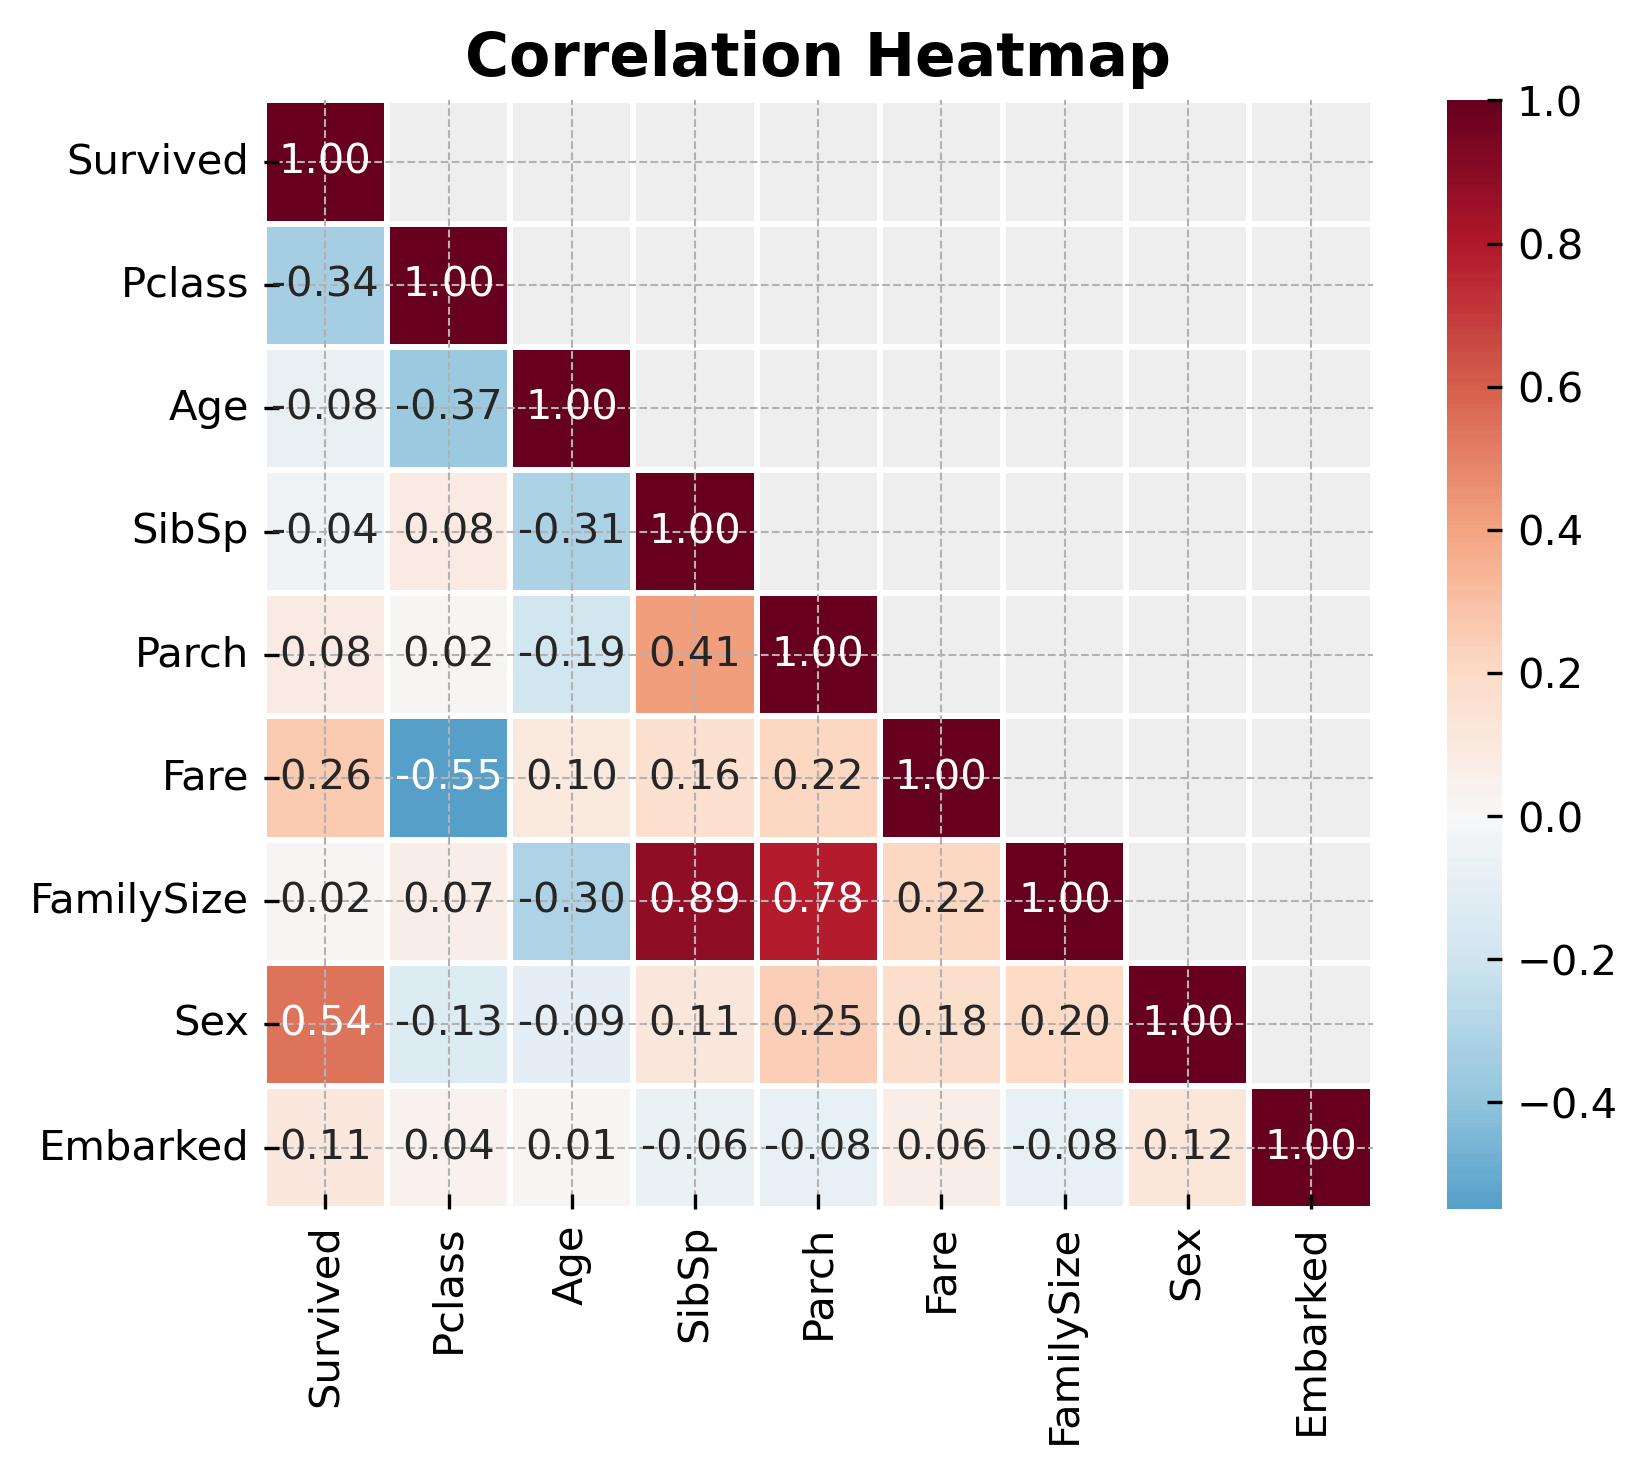

In [275]:
# create heatmap
corr = numeric_df.corr() # apply pearson correlation (r) to find correlation between two variables
mask = np.ones_like(corr, dtype=bool) # creates a boolean array where all values are True in same shape as corr
mask = np.triu(mask, k=1) # set upper triangle half of matrix to true and the rest false

# plot heatmap
fig, ax = plt.subplots(dpi=300)
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', center=0, square=True, ax=ax, cmap='RdBu_r', linewidths=1)
ax.set_title('Correlation Heatmap', weight='bold')

plt.show()

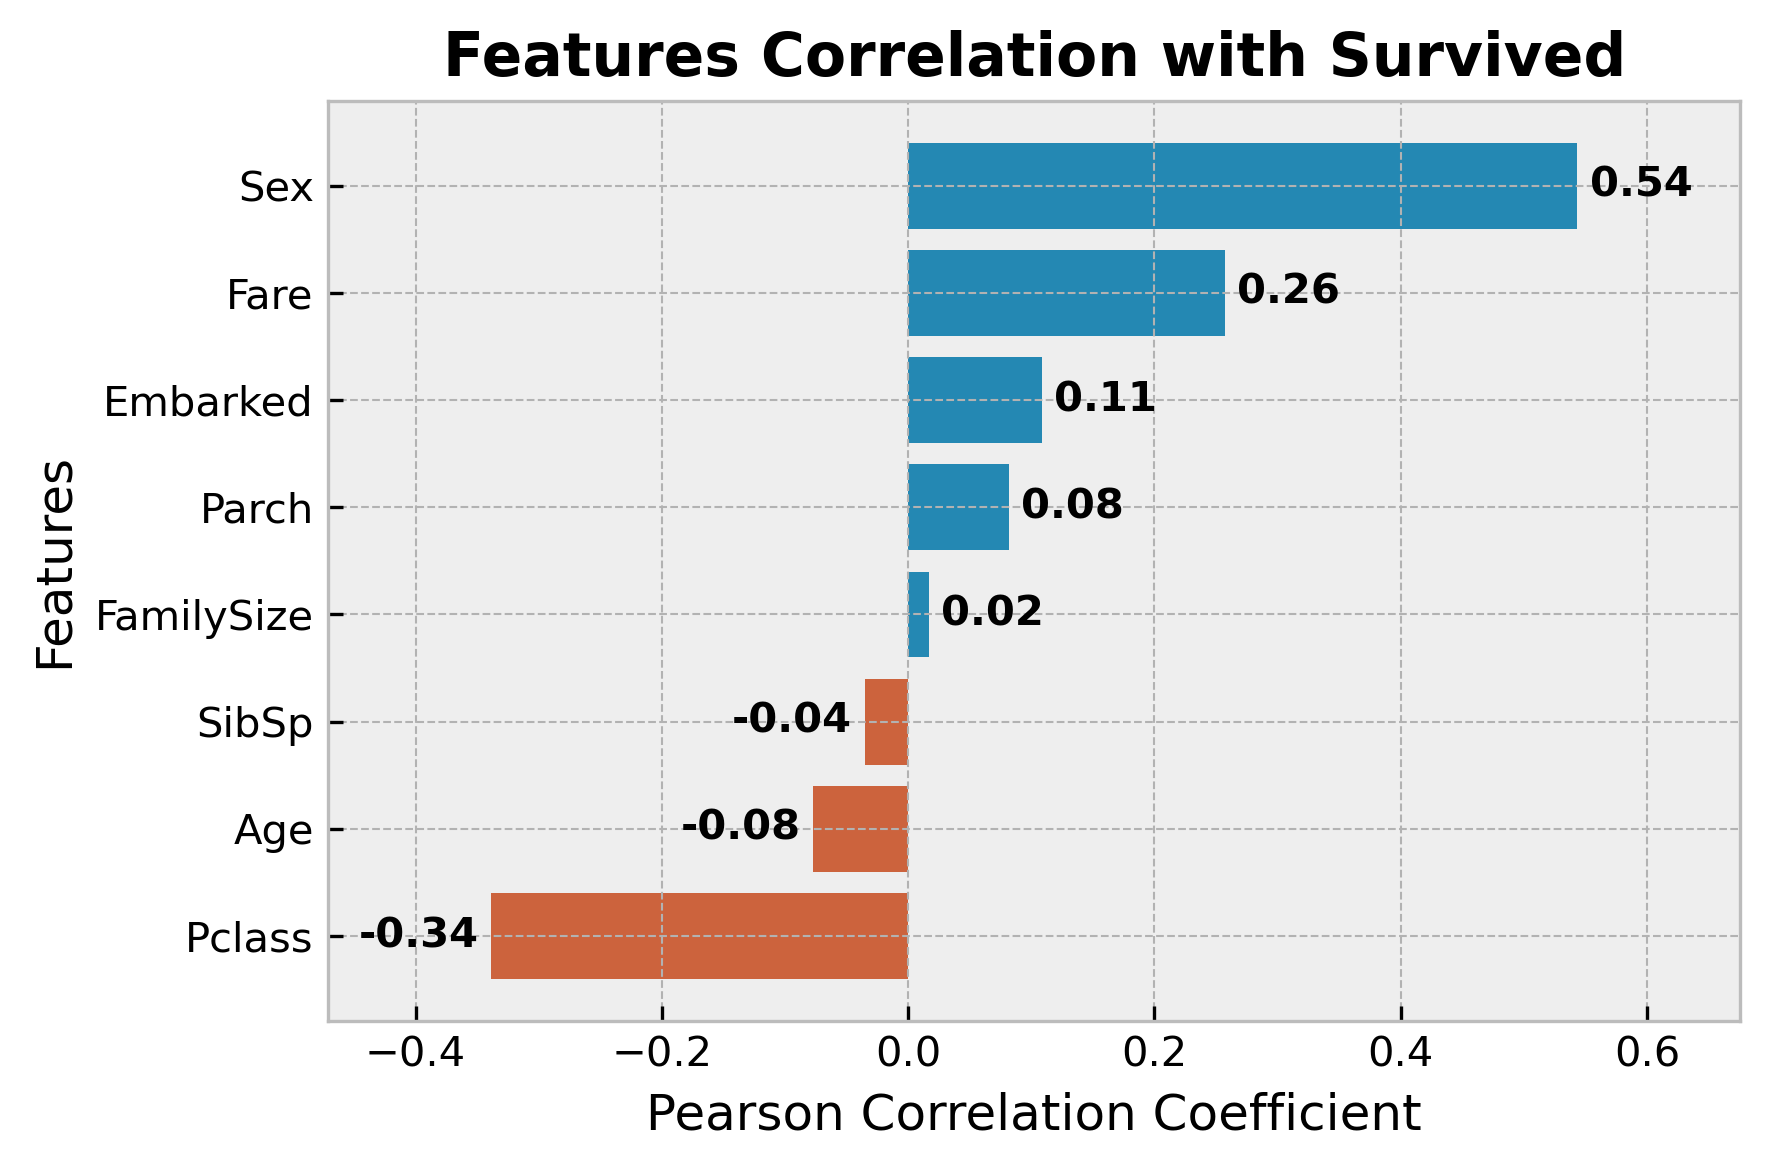

In [276]:
# correlation with target 'Survived'
survived_corr = corr['Survived'].drop('Survived').sort_values()

# set colors to blue (positive corr) and orange (negative corr)
colors = ['#2488b3' if x > 0 else '#cc633d' for x in survived_corr]

# plotting
fig, ax = plt.subplots(dpi=300, figsize=(6,4))
bars = ax.barh(survived_corr.index, survived_corr, color=colors)
ax.set_title('Features Correlation with Survived', weight='bold')
ax.set_ylabel('Features')
ax.set_xlabel('Pearson Correlation Coefficient')
ax.margins(x=0.15)

## write values onto plot
ax.bar_label(bars, fmt='%.2f', weight='bold', padding=3)

plt.tight_layout()
plt.show()

Finally, let's analyze survival rates based on a 'title'.

In [277]:
# create series for survival rate by title
df['Title'] = title
survival_title = df.groupby('Title')['Survived'].mean().sort_values()
print(survival_title)

# create series for value counts of title
values_title = title.value_counts().sort_values()
print(values_title)

Title
Capt            0.000000
Don             0.000000
Jonkheer        0.000000
Rev             0.000000
Mr              0.156673
Dr              0.428571
Col             0.500000
Major           0.500000
Master          0.575000
Miss            0.697802
Mrs             0.792000
Mme             1.000000
Sir             1.000000
Ms              1.000000
Lady            1.000000
Mlle            1.000000
the Countess    1.000000
Name: Survived, dtype: float64
0
Jonkheer          1
Mme               1
Lady              1
Sir               1
Ms                1
Capt              1
the Countess      1
Don               1
Col               2
Mlle              2
Major             2
Rev               6
Dr                7
Master           40
Mrs             125
Miss            182
Mr              517
Name: count, dtype: int64


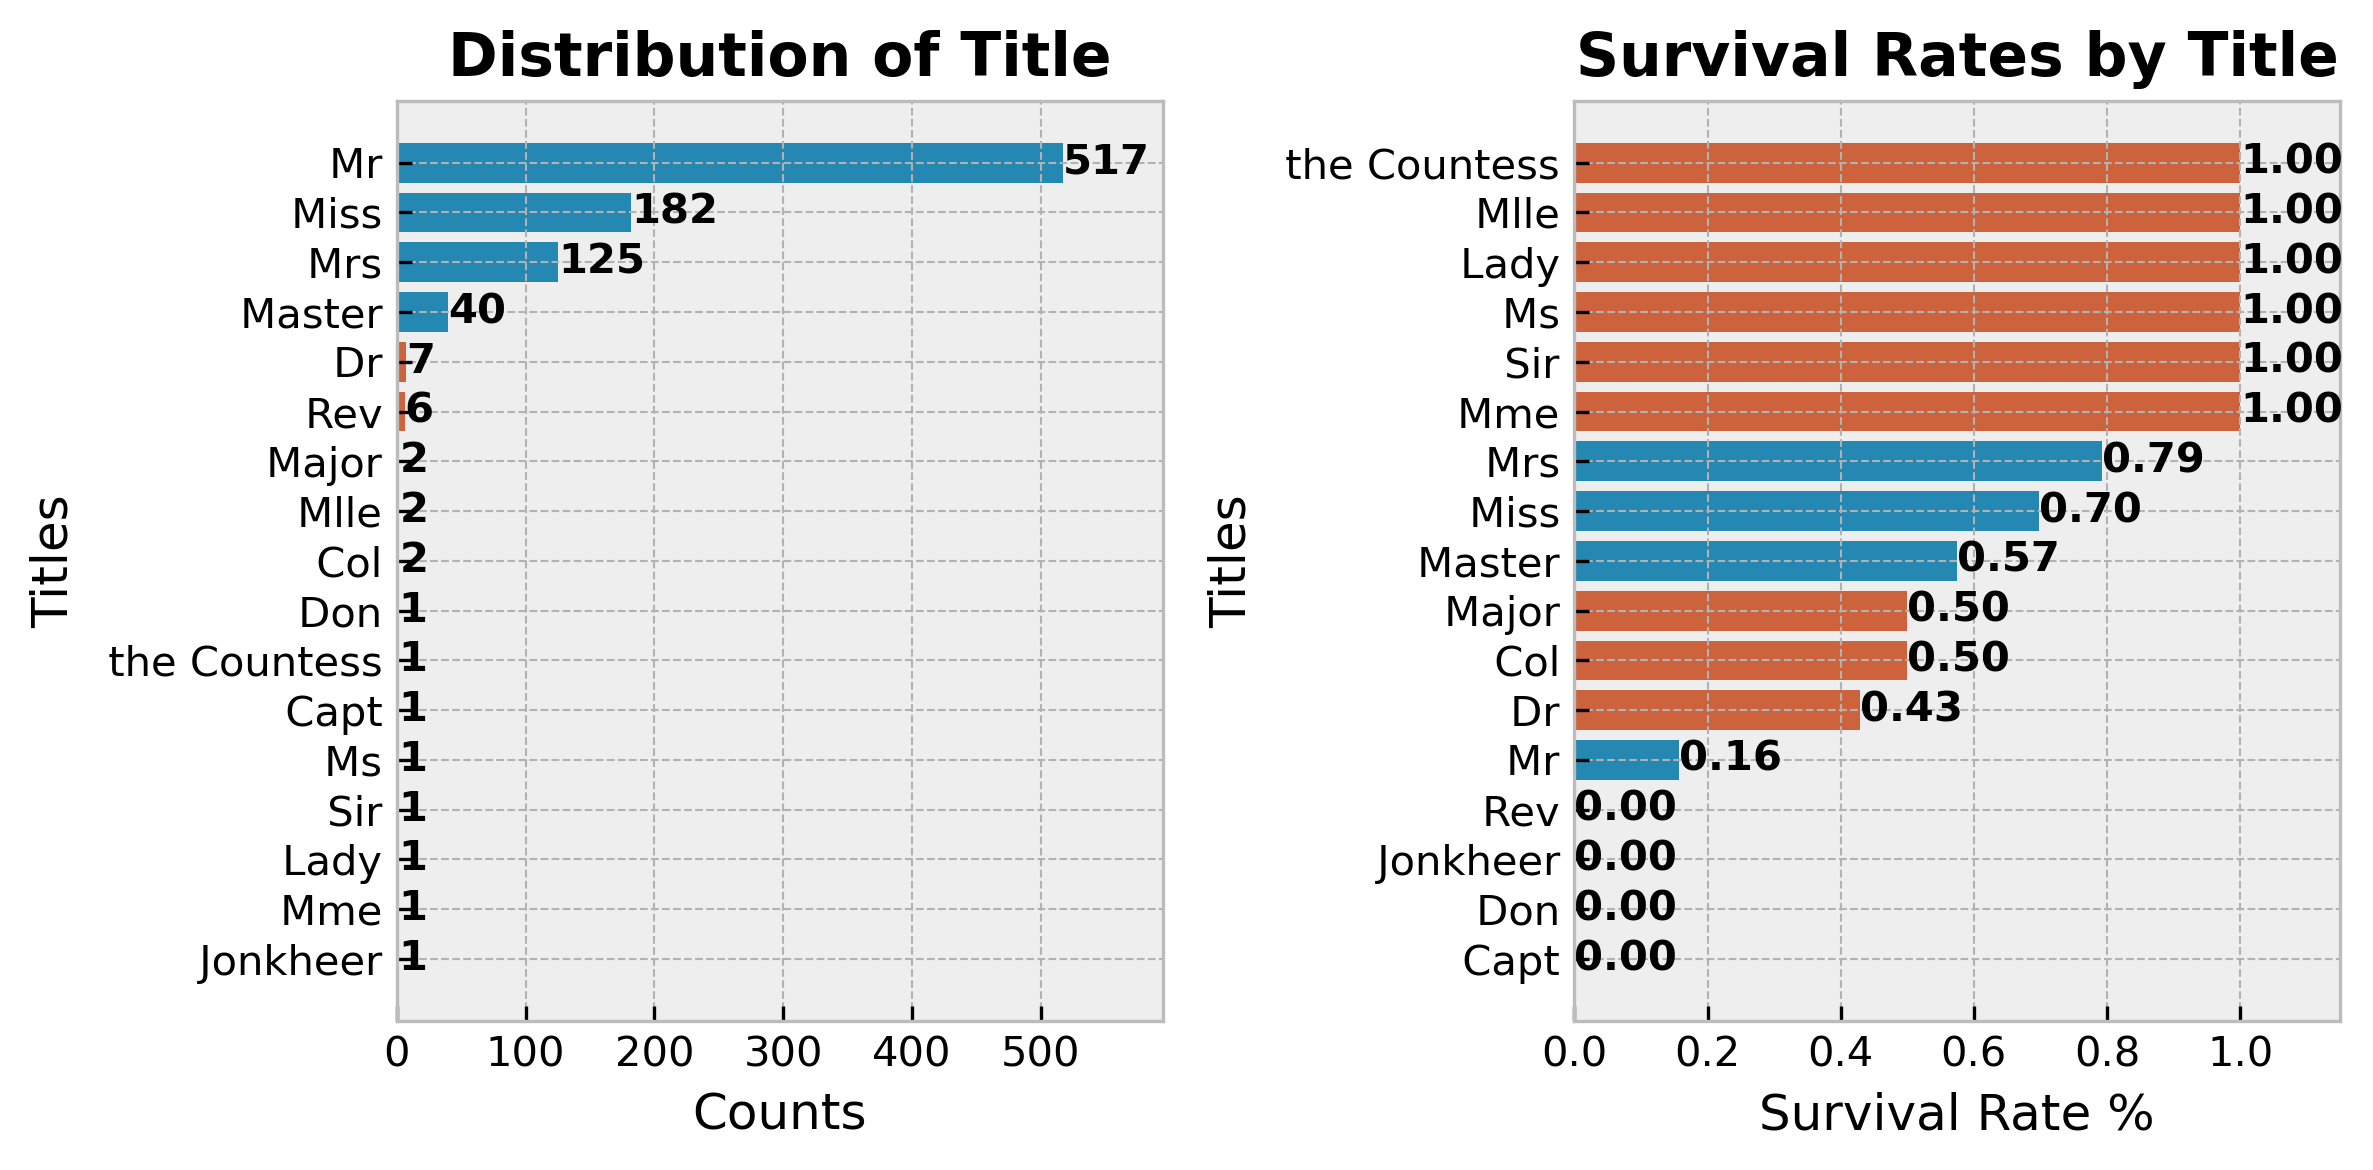

In [278]:
# plotting
fig, ax = plt.subplots(1,2, dpi=300, figsize=(8,4))

# set colors for significant columns
sig_cols = [title for title, val in values_title.items() if val >= 40]
colors_counts = ['#2488b3' if title in sig_cols else '#cc633d' for title in values_title.index]
colors_sur = ['#2488b3' if title in sig_cols else '#cc633d' for title in survival_title.index]

## plot 1: distribution of titles
ax[0].barh(values_title.index, values_title, color=colors_counts)
ax[0].set_title('Distribution of Title', weight='bold')
ax[0].set_xlabel('Counts')
ax[0].set_ylabel('Titles')
ax[0].margins(x=0.15)

## write values onto plot
for i, v in enumerate(values_title):
    ax[0].text(v, i, s=str(v), weight='bold', va='center')

## plot 2: distribution of survival rate by title
ax[1].barh(survival_title.index, survival_title, color=colors_sur)
ax[1].set_title('Survival Rates by Title', weight='bold')
ax[1].set_xlabel('Survival Rate %')
ax[1].set_ylabel('Titles')
ax[1].margins(x=0.15)

## write values onto plot
for i, v in enumerate(survival_title):
    ax[1].text(v, i, s=f'{v:.2f}', weight='bold', va='center')

plt.tight_layout()
plt.show()


## Key findings

1. `Sex` is the strongest predictor of survival 
* Women: **74.2%** survived. Men: **18.9%**
* Pearson correlation strongest of any feature **(r = 0.54)**
* The idea of "Women and children first" appears to have been followed 

2. `Pclass` and `Fare` also matter
* 1st class: **63.0%**, 2nd class: **47.3%**, 3rd class: **24.2%**
* Survivors paid more and had higher fares (median fare of **$26** for those who survived vs **$10.5** for those who died)
* `Pclass` (r = -0.34) and `Fare` (r = 0.26) were the next best predictors after `Sex`. 

3. `Sex` and `Pclass` features combined
* Women in 1st and 2nd classes had much higher survival rates compared to 3rd class: **92%** vs **50%**
* Men in 1st class had more than double the survival rate compared to 2nd and 3rd class: **37%** vs **14-16%**
* SR for 3rd class women were still higher than SR for 1st class men, consistent with sex having a higher r value than pclass

4. Age has a weak overall correlation to survival **(r = -0.08)** but we see an increase in survival rates among children. 

5. Survival rates based on port embarked from also shows some difference
* Cherbourg: **55%**, Queenstown: **39%**, Southampton: **34%**
* This is likely due to the % of `Pclass` boarding at from these ports. More analysis would be needed to confirm this. 